# M5: Text Mining & NLP Analysis

**Issues:** 18–19 (Review 2)

This notebook implements:
- **Word Frequency Analysis** — most common terms in high-rated vs low-rated movies
- **Word Clouds** — visual representation of dominant terms by rating group & genre
- **Topic Modelling (LDA)** — discover hidden themes across movie overviews
- **Sentiment Analysis** — measure emotional tone and its link to ratings
- **Genre-wise & Temporal Text Analysis** — how language differs across genres and decades

Data source: `data/processed/tmdb_clean.csv` (15,386 cleaned movies)

In [1]:
import pandas as pd
import numpy as np
import ast, re, warnings
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from wordcloud import WordCloud
from textblob import TextBlob
from collections import Counter

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
print("All imports successful.")

All imports successful.


## 1. Load and Prepare Data

In [2]:
# Load cleaned dataset
df = pd.read_csv("../data/processed/tmdb_clean.csv", parse_dates=["release_date"])
df["genres"] = df["genres"].apply(ast.literal_eval)

# Use only movies with 20+ votes (reliable ratings)
m = df[df["vote_count"] >= 20].copy()
m["high_rated"] = (m["vote_average"] >= 6.5).astype(int)
m["decade"] = (m["release_year"] // 10 * 10).astype(str) + "s"

print(f"Total clean movies: {len(df):,}")
print(f"Movies for analysis (20+ votes): {len(m):,}")
print(f"High-rated: {m['high_rated'].sum():,} ({m['high_rated'].mean():.1%})")
print(f"Low-rated: {(m['high_rated']==0).sum():,} ({(m['high_rated']==0).mean():.1%})")

Total clean movies: 15,386
Movies for analysis (20+ votes): 10,078
High-rated: 3,931 (39.0%)
Low-rated: 6,147 (61.0%)


## 2. Text Preprocessing

In [3]:
def clean_text(text):
    '''Lowercase, remove non-alpha, collapse whitespace.'''
    if pd.isna(text) or text.strip() == "":
        return ""
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

m["clean"] = m["overview"].apply(clean_text)

# Quick stats
m["word_count"] = m["clean"].str.split().str.len()
print(f"Avg words per overview: {m['word_count'].mean():.1f}")
print(f"Min: {m['word_count'].min()}, Max: {m['word_count'].max()}")
print(f"\nSample cleaned text:\n{m['clean'].iloc[0][:200]}...")

Avg words per overview: 49.6


Min: 3, Max: 195

Sample cleaned text:
the story of the legendary steel driving folk hero born with a hammer in his hands who pitted his strength against a mighty railroad building machine...


In [4]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Custom stop words: English defaults + generic movie terms
custom_stops = list(ENGLISH_STOP_WORDS) + [
    "film", "movie", "story", "life", "finds", "new", "one", "two",
    "must", "world", "man", "young", "woman", "find", "group", "takes",
    "set", "help", "time", "day", "back", "old", "gets", "makes", "just"
]
print(f"Total stop words: {len(set(custom_stops))}")

Total stop words: 338


---
## 3. Word Frequency Analysis: High-Rated vs Low-Rated

Compare the most frequently used words in high-rated movie overviews versus low-rated ones to identify thematic differences.

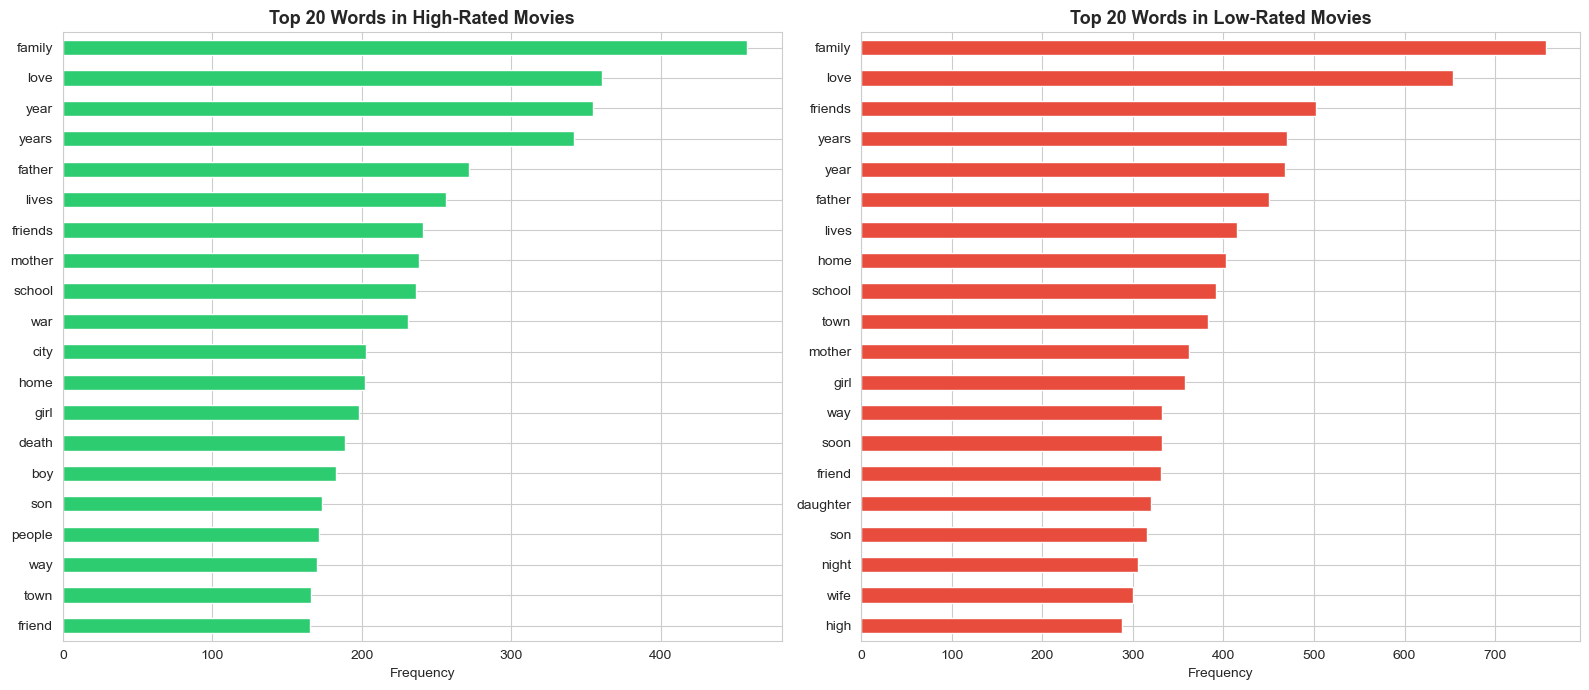

Saved: word_freq_high_vs_low.png


In [5]:
# Split texts by rating group
high_texts = m[m["high_rated"] == 1]["clean"]
low_texts = m[m["high_rated"] == 0]["clean"]

def get_word_freq(texts, stop_words):
    all_words = []
    for text in texts:
        words = [w for w in text.split() if w not in stop_words and len(w) > 2]
        all_words.extend(words)
    return Counter(all_words)

high_freq = get_word_freq(high_texts, set(custom_stops))
low_freq = get_word_freq(low_texts, set(custom_stops))

# Top 20 words per group
top_high = pd.Series(dict(high_freq.most_common(20)))
top_low = pd.Series(dict(low_freq.most_common(20)))

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
top_high.sort_values().plot(kind="barh", ax=ax[0], color="#2ecc71", edgecolor="white")
ax[0].set_title("Top 20 Words in High-Rated Movies", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Frequency")

top_low.sort_values().plot(kind="barh", ax=ax[1], color="#e74c3c", edgecolor="white")
ax[1].set_title("Top 20 Words in Low-Rated Movies", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Frequency")

plt.tight_layout()
plt.savefig("../data/processed/word_freq_high_vs_low.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: word_freq_high_vs_low.png")

### 3.1 Differential Terms (TF-IDF)

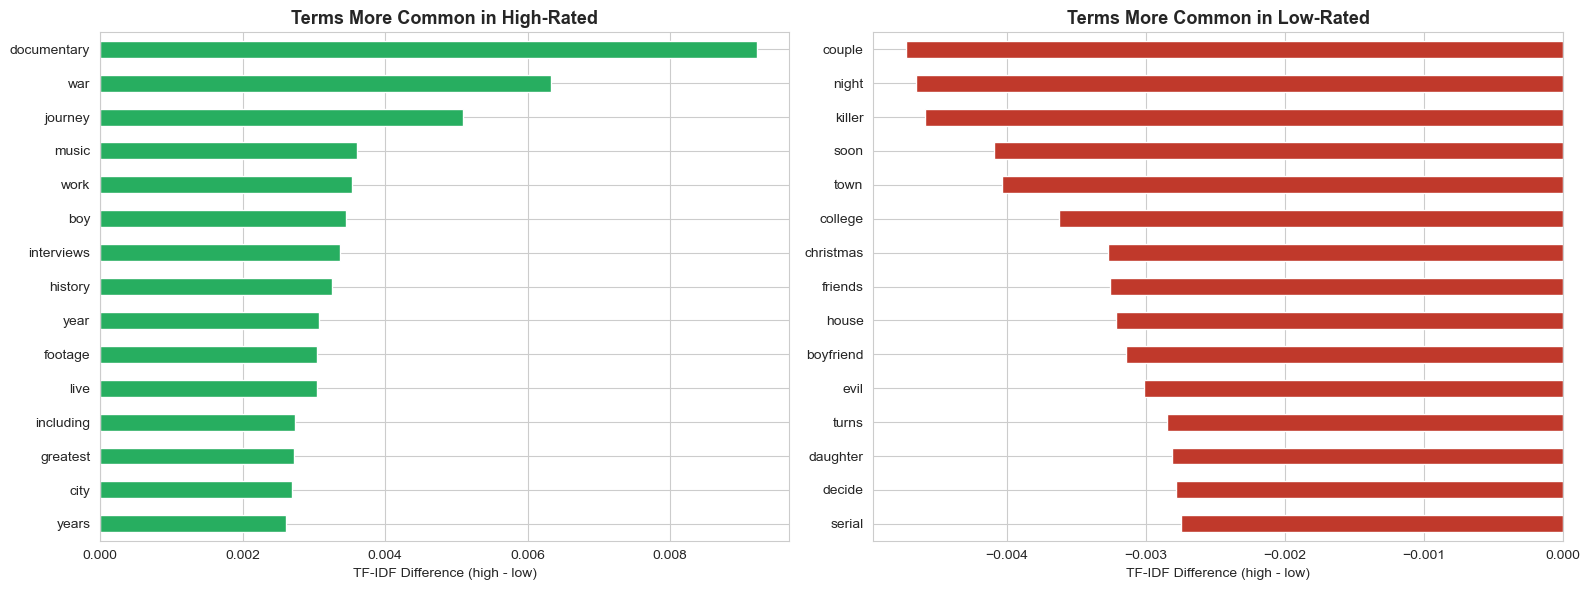

Top terms in HIGH-RATED overviews:
  documentary                +0.0092
  war                        +0.0063
  journey                    +0.0051
  music                      +0.0036
  work                       +0.0035
  boy                        +0.0034
  interviews                 +0.0034
  history                    +0.0033
  year                       +0.0031
  footage                    +0.0030
  live                       +0.0030
  including                  +0.0027
  greatest                   +0.0027
  city                       +0.0027
  years                      +0.0026

Top terms in LOW-RATED overviews:
  couple                     -0.0047
  night                      -0.0047
  killer                     -0.0046
  soon                       -0.0041
  town                       -0.0040
  college                    -0.0036
  christmas                  -0.0033
  friends                    -0.0033
  house                      -0.0032
  boyfriend                  -0.0031
  evi

In [6]:
# TF-IDF fitted on all modelling data
tfidf = TfidfVectorizer(stop_words=list(set(custom_stops)), max_features=1000,
                         ngram_range=(1, 2), min_df=5)
T = tfidf.fit_transform(m["clean"])
terms = np.array(tfidf.get_feature_names_out())

hi_mask = (m["high_rated"] == 1).values
diff = np.asarray(T[hi_mask].mean(axis=0)).ravel() - np.asarray(T[~hi_mask].mean(axis=0)).ravel()

top_high_tfidf = pd.Series(diff, index=terms).sort_values(ascending=False).head(15)
top_low_tfidf = pd.Series(diff, index=terms).sort_values(ascending=True).head(15)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
top_high_tfidf.sort_values().plot(kind="barh", ax=ax[0], color="#27ae60")
ax[0].set_title("Terms More Common in High-Rated", fontsize=13, fontweight="bold")
ax[0].set_xlabel("TF-IDF Difference (high - low)")

top_low_tfidf.sort_values(ascending=False).plot(kind="barh", ax=ax[1], color="#c0392b")
ax[1].set_title("Terms More Common in Low-Rated", fontsize=13, fontweight="bold")
ax[1].set_xlabel("TF-IDF Difference (high - low)")

plt.tight_layout()
plt.savefig("../data/processed/differential_terms.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top terms in HIGH-RATED overviews:")
for t, v in top_high_tfidf.items():
    print(f"  {t:25s}  +{v:.4f}")
print("\nTop terms in LOW-RATED overviews:")
for t, v in top_low_tfidf.items():
    print(f"  {t:25s}  {v:.4f}")

---
## 4. Word Clouds

Visual representation of dominant terms in high-rated versus low-rated movie overviews.

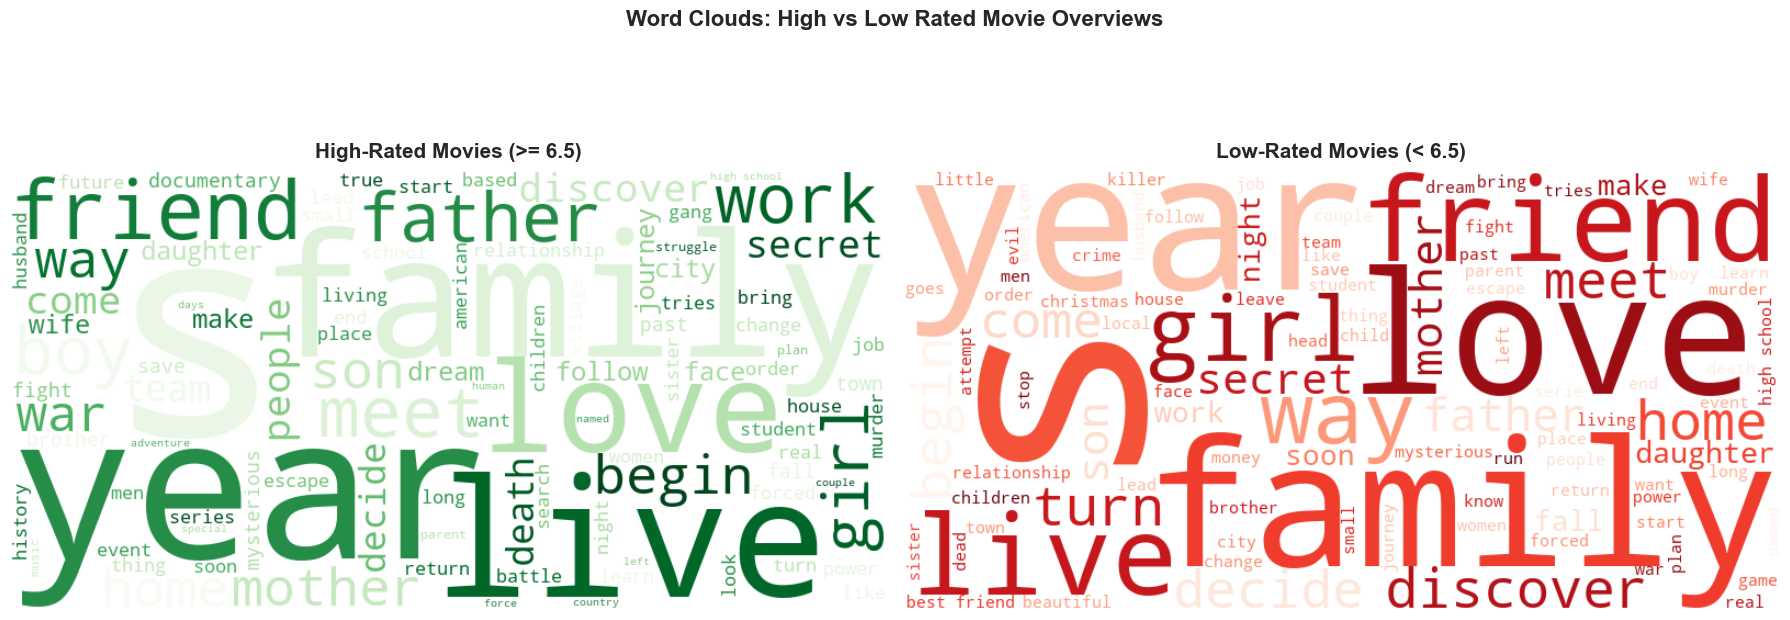

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(18, 7))

wc_high = WordCloud(width=800, height=400, background_color="white",
                     colormap="Greens", max_words=100,
                     stopwords=set(custom_stops)).generate(" ".join(high_texts))
ax[0].imshow(wc_high, interpolation="bilinear")
ax[0].set_title("High-Rated Movies (>= 6.5)", fontsize=15, fontweight="bold", pad=10)
ax[0].axis("off")

wc_low = WordCloud(width=800, height=400, background_color="white",
                    colormap="Reds", max_words=100,
                    stopwords=set(custom_stops)).generate(" ".join(low_texts))
ax[1].imshow(wc_low, interpolation="bilinear")
ax[1].set_title("Low-Rated Movies (< 6.5)", fontsize=15, fontweight="bold", pad=10)
ax[1].axis("off")

plt.suptitle("Word Clouds: High vs Low Rated Movie Overviews", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../data/processed/wordclouds_rating.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.1 Word Clouds by Genre

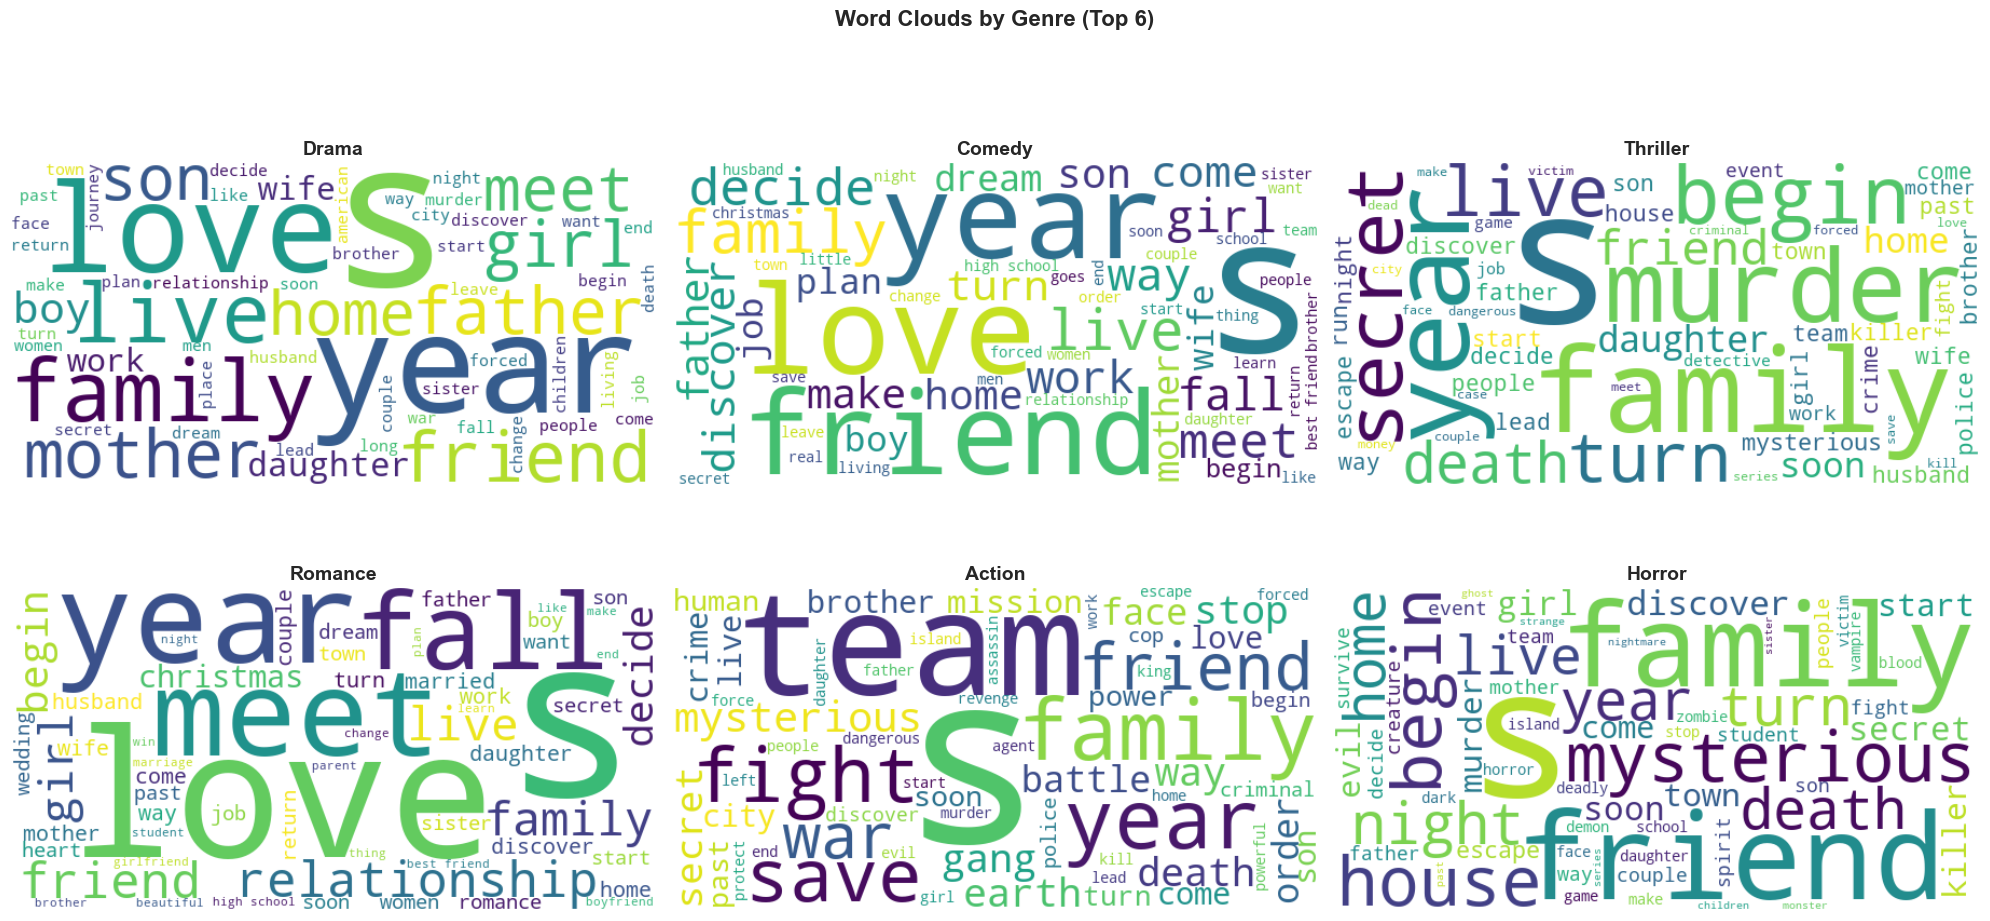

In [8]:
# Word clouds for top 6 genres by movie count
g = m.explode("genres").reset_index(drop=True)
top_genres = g["genres"].value_counts().head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for i, genre in enumerate(top_genres):
    ax = axes[i // 3, i % 3]
    genre_text = " ".join(g[g["genres"] == genre]["clean"])
    wc = WordCloud(width=600, height=300, background_color="white",
                    colormap="viridis", max_words=60,
                    stopwords=set(custom_stops)).generate(genre_text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(genre, fontsize=14, fontweight="bold")
    ax.axis("off")

plt.suptitle("Word Clouds by Genre (Top 6)", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("../data/processed/wordclouds_genre.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 5. Topic Modelling (Latent Dirichlet Allocation)

LDA discovers hidden "topics" — groups of words that frequently co-occur across overviews. Each movie gets a distribution over topics.

In [9]:
# Use CountVectorizer for LDA (needs raw counts, not TF-IDF)
count_vec = CountVectorizer(stop_words=list(set(custom_stops)), max_features=2000,
                             ngram_range=(1, 1), min_df=10, max_df=0.7)
doc_term = count_vec.fit_transform(m["clean"])
feature_names = count_vec.get_feature_names_out()

# Fit LDA with 8 topics
N_TOPICS = 8
lda = LatentDirichletAllocation(n_components=N_TOPICS, random_state=42,
                                  max_iter=20, learning_method="online")
topic_dist = lda.fit_transform(doc_term)

print(f"Documents: {doc_term.shape[0]:,}")
print(f"Vocabulary: {doc_term.shape[1]:,}")
print(f"Topics discovered: {N_TOPICS}")
print(f"Log-likelihood: {lda.score(doc_term):.0f}")
print(f"Perplexity: {lda.perplexity(doc_term):.0f}")

Documents: 10,078
Vocabulary: 2,000
Topics discovered: 8


Log-likelihood: -1113988


Perplexity: 1899


### 5.1 Discovered Topics

In [10]:
# Display top words per topic
def display_topics(model, feature_names, n_words=10):
    topics = []
    for i, topic in enumerate(model.components_):
        top_words = [feature_names[j] for j in topic.argsort()[:-n_words-1:-1]]
        topics.append({"Topic": f"Topic {i+1}", "Top Words": ", ".join(top_words)})
        print(f"Topic {i+1}: {', '.join(top_words)}")
    return pd.DataFrame(topics)

print("=== Discovered Topics (Top 10 Words Each) ===\n")
topic_df = display_topics(lda, feature_names, n_words=10)

=== Discovered Topics (Top 10 Words Each) ===

Topic 1: war, search, documentary, game, based, true, adventure, agent, history, detective
Topic 2: police, murder, killer, dead, case, crime, criminal, missing, following, investigation
Topic 3: friends, couple, night, home, turns, relationship, married, soon, comes, begins
Topic 4: family, father, brother, like, way, money, year, face, friends, people
Topic 5: school, high, year, days, student, people, team, different, girl, middle
Topic 6: father, year, parents, mysterious, leads, friend, mother, home, begins, death
Topic 7: love, son, family, daughter, wife, meets, falls, girl, village, star
Topic 8: town, past, family, christmas, small, away, years, island, plan, city


### 5.2 Topic vs Rating Analysis

=== Rating by Dominant Topic ===
                count  avg_rating  high_rated_pct  avg_popularity
dominant_topic                                                   
1                1266       6.268           0.474           3.555
2                 719       5.967           0.316           3.478
3                1241       5.997           0.336           3.205
4                2515       6.085           0.380           3.495
5                1062       6.171           0.416           3.192
6                1131       6.158           0.402           3.507
7                1128       6.224           0.415           3.204
8                1016       6.091           0.360           3.534


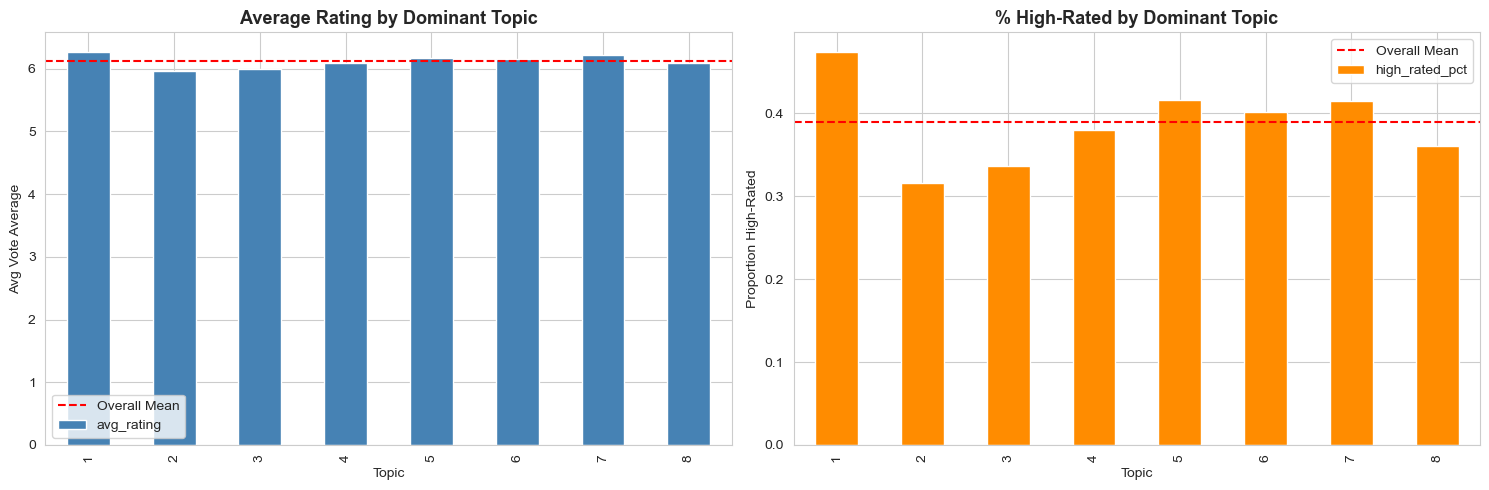

In [11]:
# Assign dominant topic to each movie
m["dominant_topic"] = topic_dist.argmax(axis=1) + 1

# Average rating per dominant topic
topic_rating = m.groupby("dominant_topic").agg(
    count=("high_rated", "count"),
    avg_rating=("vote_average", "mean"),
    high_rated_pct=("high_rated", "mean"),
    avg_popularity=("popularity", "mean")
).round(3)

print("=== Rating by Dominant Topic ===")
print(topic_rating.to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

topic_rating["avg_rating"].plot(kind="bar", ax=ax[0], color="steelblue", edgecolor="white")
ax[0].set_title("Average Rating by Dominant Topic", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Topic")
ax[0].set_ylabel("Avg Vote Average")
ax[0].axhline(y=m["vote_average"].mean(), color="red", linestyle="--", label="Overall Mean")
ax[0].legend()

topic_rating["high_rated_pct"].plot(kind="bar", ax=ax[1], color="darkorange", edgecolor="white")
ax[1].set_title("% High-Rated by Dominant Topic", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Topic")
ax[1].set_ylabel("Proportion High-Rated")
ax[1].axhline(y=m["high_rated"].mean(), color="red", linestyle="--", label="Overall Mean")
ax[1].legend()

plt.tight_layout()
plt.savefig("../data/processed/topic_vs_rating.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Topic-Genre Heatmap

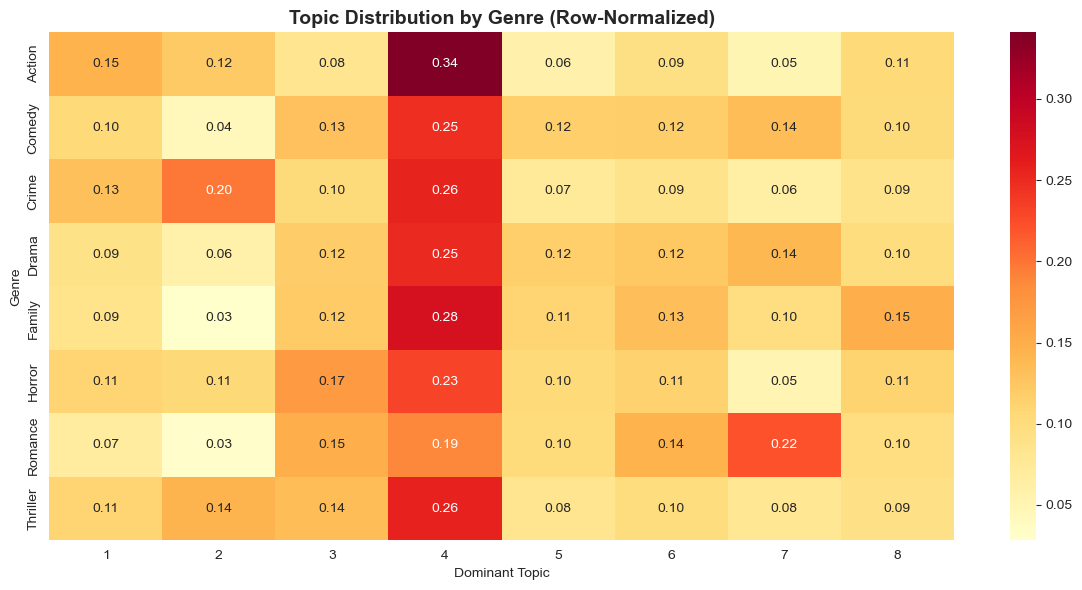


Each row shows what fraction of movies in that genre belong to each topic.


In [12]:
# Cross-tabulate dominant topic vs genre
g_topics = m.explode("genres").reset_index(drop=True)
top_genres_8 = g_topics["genres"].value_counts().head(8).index.tolist()
g_topics = g_topics[g_topics["genres"].isin(top_genres_8)]

cross = pd.crosstab(g_topics["genres"], g_topics["dominant_topic"], normalize="index")

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(cross, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax)
ax.set_title("Topic Distribution by Genre (Row-Normalized)", fontsize=14, fontweight="bold")
ax.set_xlabel("Dominant Topic")
ax.set_ylabel("Genre")
plt.tight_layout()
plt.savefig("../data/processed/topic_genre_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nEach row shows what fraction of movies in that genre belong to each topic.")

---
## 6. Sentiment Analysis

Measure the polarity (positive/negative tone) and subjectivity (opinion vs fact) of each overview using TextBlob.

In [13]:
# Calculate sentiment scores
m["polarity"] = m["overview"].apply(lambda x: TextBlob(str(x)).sentiment.polarity)
m["subjectivity"] = m["overview"].apply(lambda x: TextBlob(str(x)).sentiment.subjectivity)

print("=== Sentiment Summary ===")
print(m[["polarity", "subjectivity"]].describe().round(3))

print(f"\nBy rating group:")
print(m.groupby("high_rated")[["polarity", "subjectivity"]].mean().round(4).rename(
    index={0: "Low-rated", 1: "High-rated"}))

=== Sentiment Summary ===
        polarity  subjectivity
count  10078.000     10078.000
mean       0.047         0.465
std        0.228         0.227
min       -1.000         0.000
25%       -0.065         0.333
50%        0.034         0.476
75%        0.172         0.601
max        1.000         1.000

By rating group:
            polarity  subjectivity
high_rated                        
Low-rated     0.0364        0.4701
High-rated    0.0647        0.4581


### 6.1 Sentiment Distribution

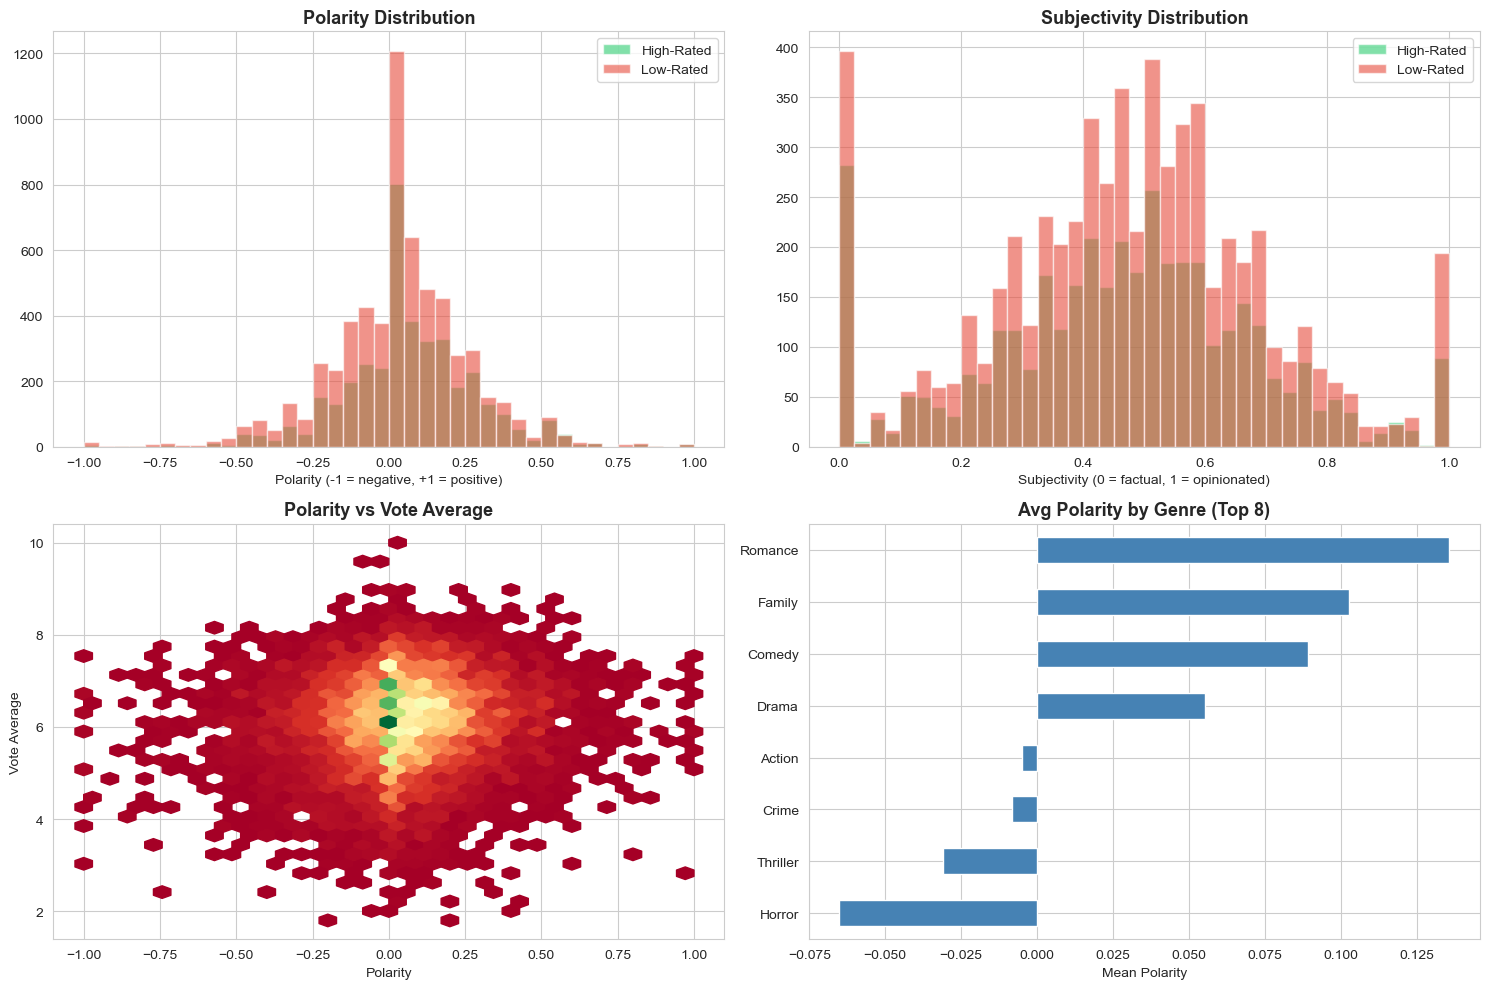

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# Polarity distribution by rating
for label, color, name in [(1, "#2ecc71", "High-Rated"), (0, "#e74c3c", "Low-Rated")]:
    subset = m[m["high_rated"] == label]["polarity"]
    ax[0, 0].hist(subset, bins=40, alpha=0.6, color=color, label=name, edgecolor="white")
ax[0, 0].set_title("Polarity Distribution", fontsize=13, fontweight="bold")
ax[0, 0].set_xlabel("Polarity (-1 = negative, +1 = positive)")
ax[0, 0].legend()

# Subjectivity distribution by rating
for label, color, name in [(1, "#2ecc71", "High-Rated"), (0, "#e74c3c", "Low-Rated")]:
    subset = m[m["high_rated"] == label]["subjectivity"]
    ax[0, 1].hist(subset, bins=40, alpha=0.6, color=color, label=name, edgecolor="white")
ax[0, 1].set_title("Subjectivity Distribution", fontsize=13, fontweight="bold")
ax[0, 1].set_xlabel("Subjectivity (0 = factual, 1 = opinionated)")
ax[0, 1].legend()

# Polarity vs Rating scatter
ax[1, 0].hexbin(m["polarity"], m["vote_average"], gridsize=35, cmap="RdYlGn", mincnt=1)
ax[1, 0].set_title("Polarity vs Vote Average", fontsize=13, fontweight="bold")
ax[1, 0].set_xlabel("Polarity")
ax[1, 0].set_ylabel("Vote Average")

# Sentiment by genre (top 8)
g_sent = m.explode("genres").reset_index(drop=True)
top8 = g_sent["genres"].value_counts().head(8).index
g_sent = g_sent[g_sent["genres"].isin(top8)]
genre_sent = g_sent.groupby("genres")["polarity"].mean().sort_values()
genre_sent.plot(kind="barh", ax=ax[1, 1], color="steelblue", edgecolor="white")
ax[1, 1].set_title("Avg Polarity by Genre (Top 8)", fontsize=13, fontweight="bold")
ax[1, 1].set_xlabel("Mean Polarity")
ax[1, 1].set_ylabel("")

plt.tight_layout()
plt.savefig("../data/processed/sentiment_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.2 Sentiment Correlation with Rating

In [15]:
from scipy.stats import spearmanr

corr_pol, p_pol = spearmanr(m["polarity"], m["vote_average"])
corr_sub, p_sub = spearmanr(m["subjectivity"], m["vote_average"])

print("=== Spearman Correlations with Vote Average ===")
print(f"Polarity:     r = {corr_pol:.4f}  (p = {p_pol:.2e})")
print(f"Subjectivity: r = {corr_sub:.4f}  (p = {p_sub:.2e})")
print()
if abs(corr_pol) < 0.1:
    print("Polarity has negligible correlation with rating.")
else:
    direction = "positive" if corr_pol > 0 else "negative"
    print(f"Polarity has a {direction} weak correlation with rating.")

if abs(corr_sub) < 0.1:
    print("Subjectivity has negligible correlation with rating.")
else:
    direction = "positive" if corr_sub > 0 else "negative"
    print(f"Subjectivity has a {direction} weak correlation with rating.")

=== Spearman Correlations with Vote Average ===
Polarity:     r = 0.0833  (p = 5.48e-17)
Subjectivity: r = -0.0346  (p = 5.09e-04)

Polarity has negligible correlation with rating.
Subjectivity has negligible correlation with rating.


---
## 7. Temporal Text Analysis

How has the language of movie overviews changed across decades?

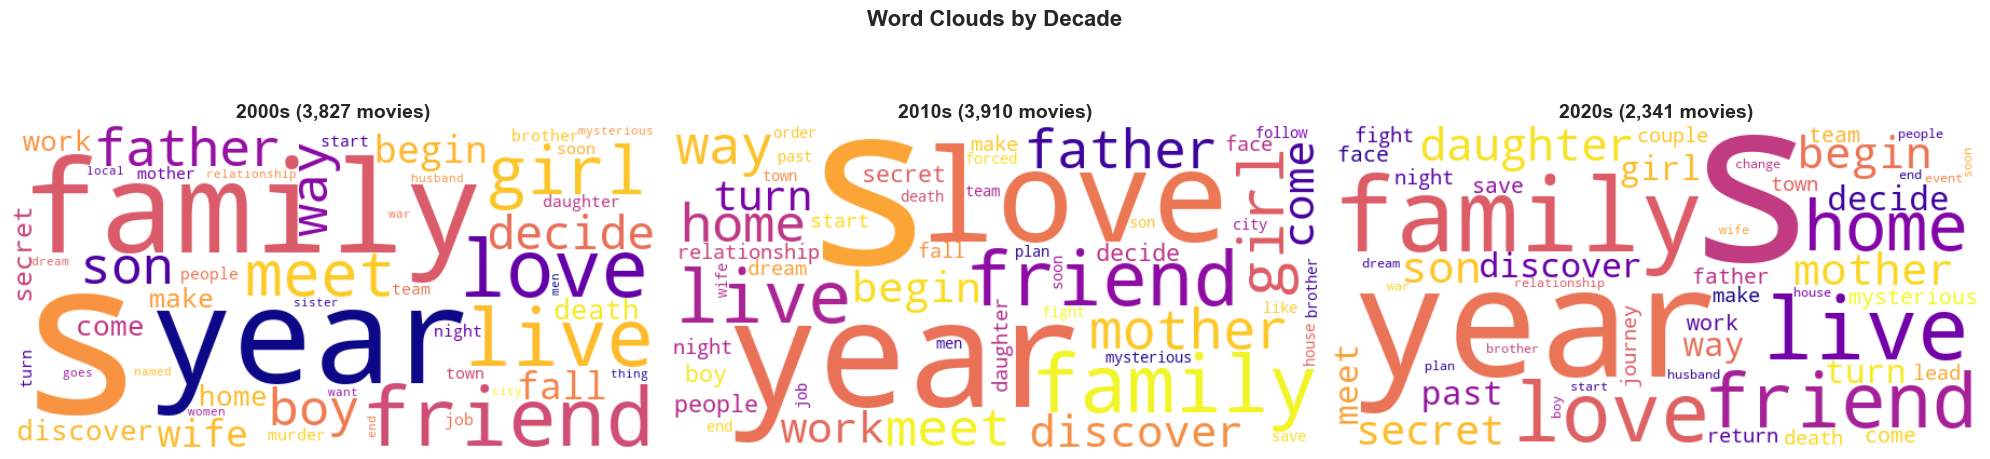

In [16]:
decades = ["2000s", "2010s", "2020s"]
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for i, decade in enumerate(decades):
    decade_text = " ".join(m[m["decade"] == decade]["clean"])
    wc = WordCloud(width=600, height=300, background_color="white",
                    colormap="plasma", max_words=50,
                    stopwords=set(custom_stops)).generate(decade_text)
    axes[i].imshow(wc, interpolation="bilinear")
    n_movies = (m["decade"] == decade).sum()
    axes[i].set_title(f"{decade} ({n_movies:,} movies)", fontsize=14, fontweight="bold")
    axes[i].axis("off")

plt.suptitle("Word Clouds by Decade", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../data/processed/wordclouds_decade.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.1 Sentiment Trends Over Time

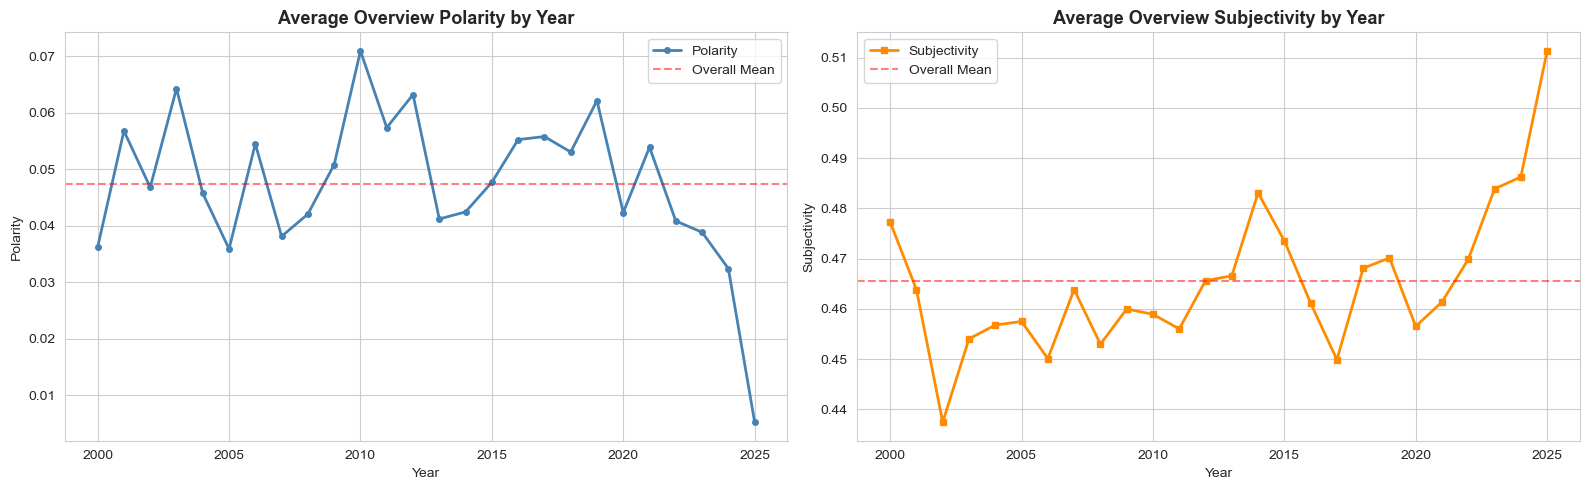

In [17]:
yearly_sent = m.groupby("release_year").agg(
    avg_polarity=("polarity", "mean"),
    avg_subjectivity=("subjectivity", "mean"),
    avg_rating=("vote_average", "mean"),
    count=("high_rated", "count")
)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

ax[0].plot(yearly_sent.index, yearly_sent["avg_polarity"], color="steelblue",
           marker="o", markersize=4, linewidth=2, label="Polarity")
ax[0].set_title("Average Overview Polarity by Year", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Year")
ax[0].set_ylabel("Polarity")
ax[0].axhline(y=m["polarity"].mean(), color="red", linestyle="--", alpha=0.5, label="Overall Mean")
ax[0].legend()

ax[1].plot(yearly_sent.index, yearly_sent["avg_subjectivity"], color="darkorange",
           marker="s", markersize=4, linewidth=2, label="Subjectivity")
ax[1].set_title("Average Overview Subjectivity by Year", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Year")
ax[1].set_ylabel("Subjectivity")
ax[1].axhline(y=m["subjectivity"].mean(), color="red", linestyle="--", alpha=0.5, label="Overall Mean")
ax[1].legend()

plt.tight_layout()
plt.savefig("../data/processed/sentiment_trends.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 8. Overview Length Analysis

Does the length of a movie overview relate to its rating?

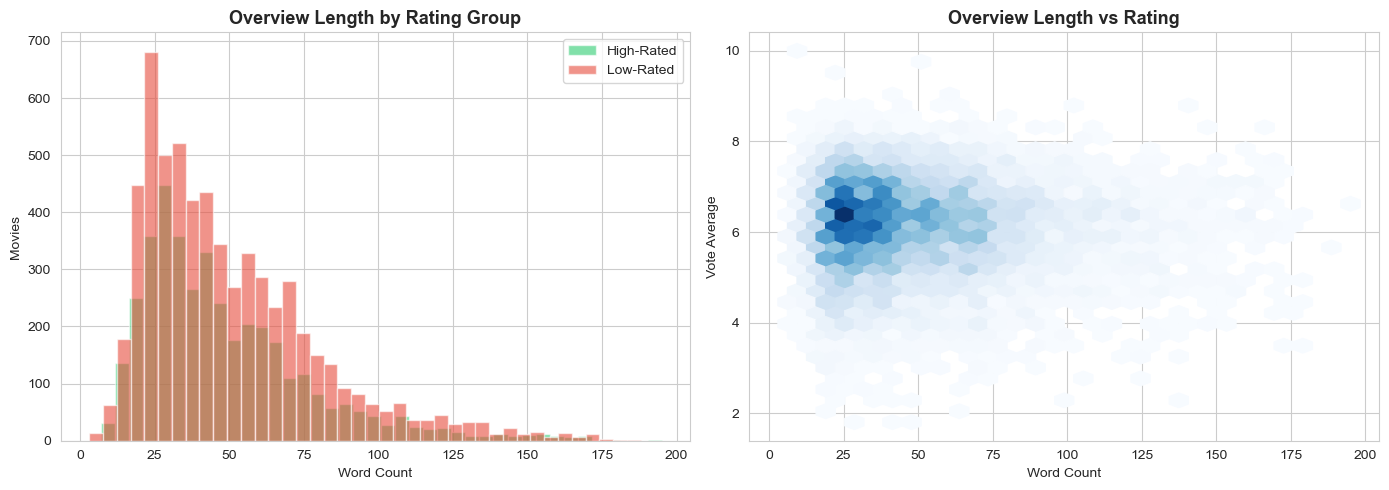

Spearman correlation (word count vs rating): r = -0.0144  (p = 1.49e-01)
Avg words -- High-rated: 48.7 | Low-rated: 50.1


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Word count distribution by rating group
for label, color, name in [(1, "#2ecc71", "High-Rated"), (0, "#e74c3c", "Low-Rated")]:
    subset = m[m["high_rated"] == label]["word_count"]
    ax[0].hist(subset, bins=40, alpha=0.6, color=color, label=name, edgecolor="white")
ax[0].set_title("Overview Length by Rating Group", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Word Count")
ax[0].set_ylabel("Movies")
ax[0].legend()

# Hexbin: word count vs rating
ax[1].hexbin(m["word_count"], m["vote_average"], gridsize=30, cmap="Blues", mincnt=1)
ax[1].set_title("Overview Length vs Rating", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Word Count")
ax[1].set_ylabel("Vote Average")

plt.tight_layout()
plt.savefig("../data/processed/overview_length.png", dpi=150, bbox_inches="tight")
plt.show()

corr_wc, p_wc = spearmanr(m["word_count"], m["vote_average"])
print(f"Spearman correlation (word count vs rating): r = {corr_wc:.4f}  (p = {p_wc:.2e})")
hi_wc = m[m["high_rated"]==1]["word_count"].mean()
lo_wc = m[m["high_rated"]==0]["word_count"].mean()
print(f"Avg words -- High-rated: {hi_wc:.1f} | Low-rated: {lo_wc:.1f}")

---
## 9. N-gram Analysis (Bigrams & Trigrams)

Single words miss context. Bigrams like "serial killer" or "falls love" reveal richer thematic patterns.

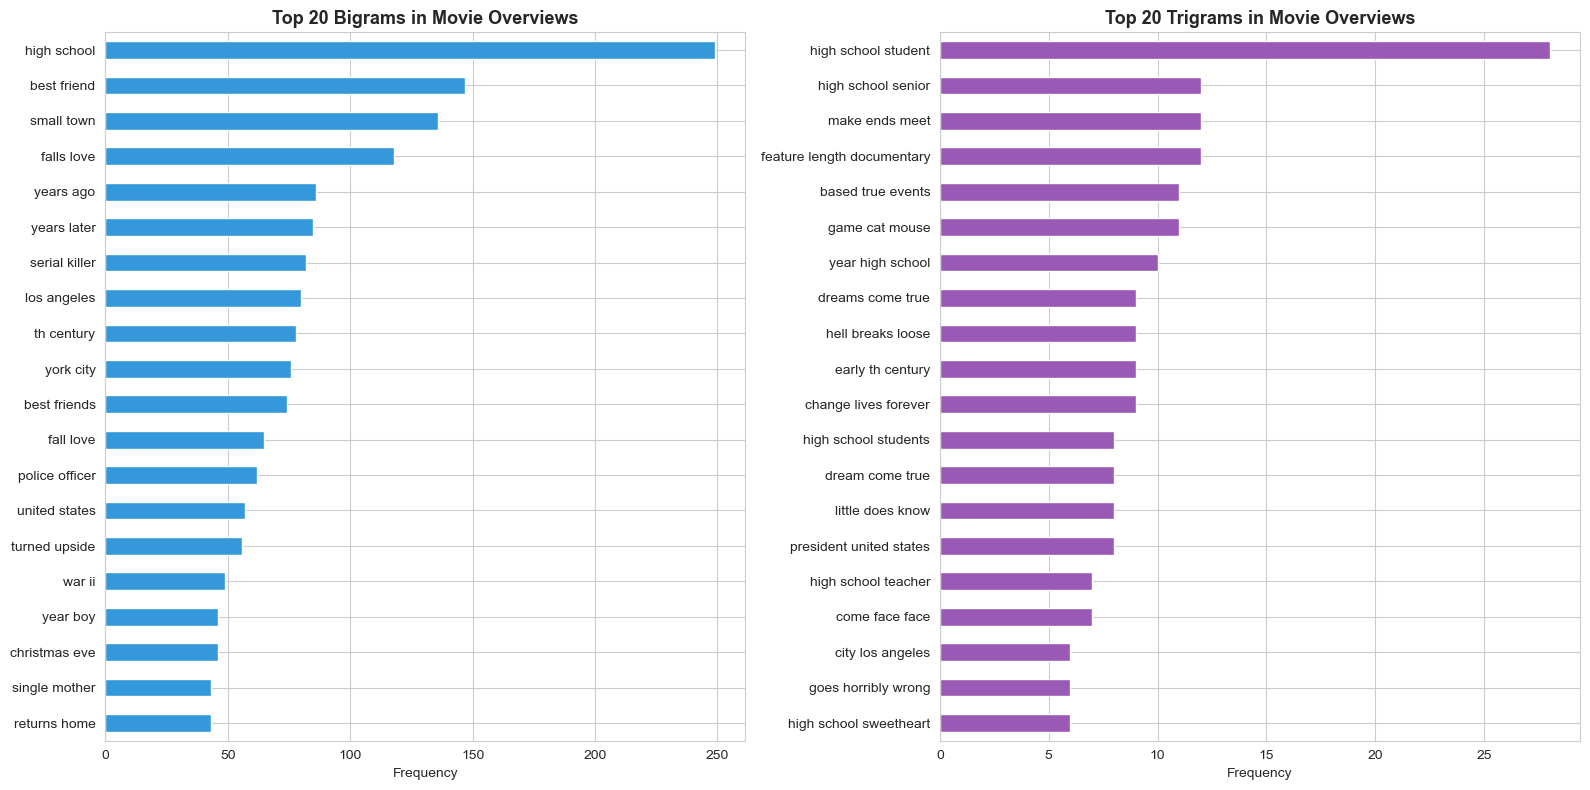

=== Top 15 Bigrams ===
  high school                     249
  best friend                     147
  small town                      136
  falls love                      118
  years ago                       86
  years later                     85
  serial killer                   82
  los angeles                     80
  th century                      78
  york city                       76
  best friends                    74
  fall love                       65
  police officer                  62
  united states                   57
  turned upside                   56

=== Top 15 Trigrams ===
  high school student                  28
  feature length documentary           12
  make ends meet                       12
  high school senior                   12
  based true events                    11
  game cat mouse                       11
  year high school                     10
  change lives forever                 9
  hell breaks loose                    9
  dreams come tru

In [19]:
# Bigram Analysis
bigram_vec = CountVectorizer(ngram_range=(2,2), stop_words=list(set(custom_stops)), 
                              max_features=500, min_df=5)
bigrams_matrix = bigram_vec.fit_transform(m["clean"])
bigram_freq = pd.Series(bigrams_matrix.sum(axis=0).A1, 
                         index=bigram_vec.get_feature_names_out()).sort_values(ascending=False)

# Trigram Analysis
trigram_vec = CountVectorizer(ngram_range=(3,3), stop_words=list(set(custom_stops)), 
                               max_features=500, min_df=5)
trigrams_matrix = trigram_vec.fit_transform(m["clean"])
trigram_freq = pd.Series(trigrams_matrix.sum(axis=0).A1, 
                          index=trigram_vec.get_feature_names_out()).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 8))

bigram_freq.head(20).sort_values().plot(kind="barh", ax=ax[0], color="#3498db", edgecolor="white")
ax[0].set_title("Top 20 Bigrams in Movie Overviews", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Frequency")

trigram_freq.head(20).sort_values().plot(kind="barh", ax=ax[1], color="#9b59b6", edgecolor="white")
ax[1].set_title("Top 20 Trigrams in Movie Overviews", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Frequency")

plt.tight_layout()
plt.savefig("../data/processed/ngram_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

print("=== Top 15 Bigrams ===")
for term, freq in bigram_freq.head(15).items():
    print(f"  {term:30s}  {freq:,}")
print("\n=== Top 15 Trigrams ===")
for term, freq in trigram_freq.head(15).items():
    print(f"  {term:35s}  {freq:,}")

### 9.1 Differential Bigrams: High vs Low Rated

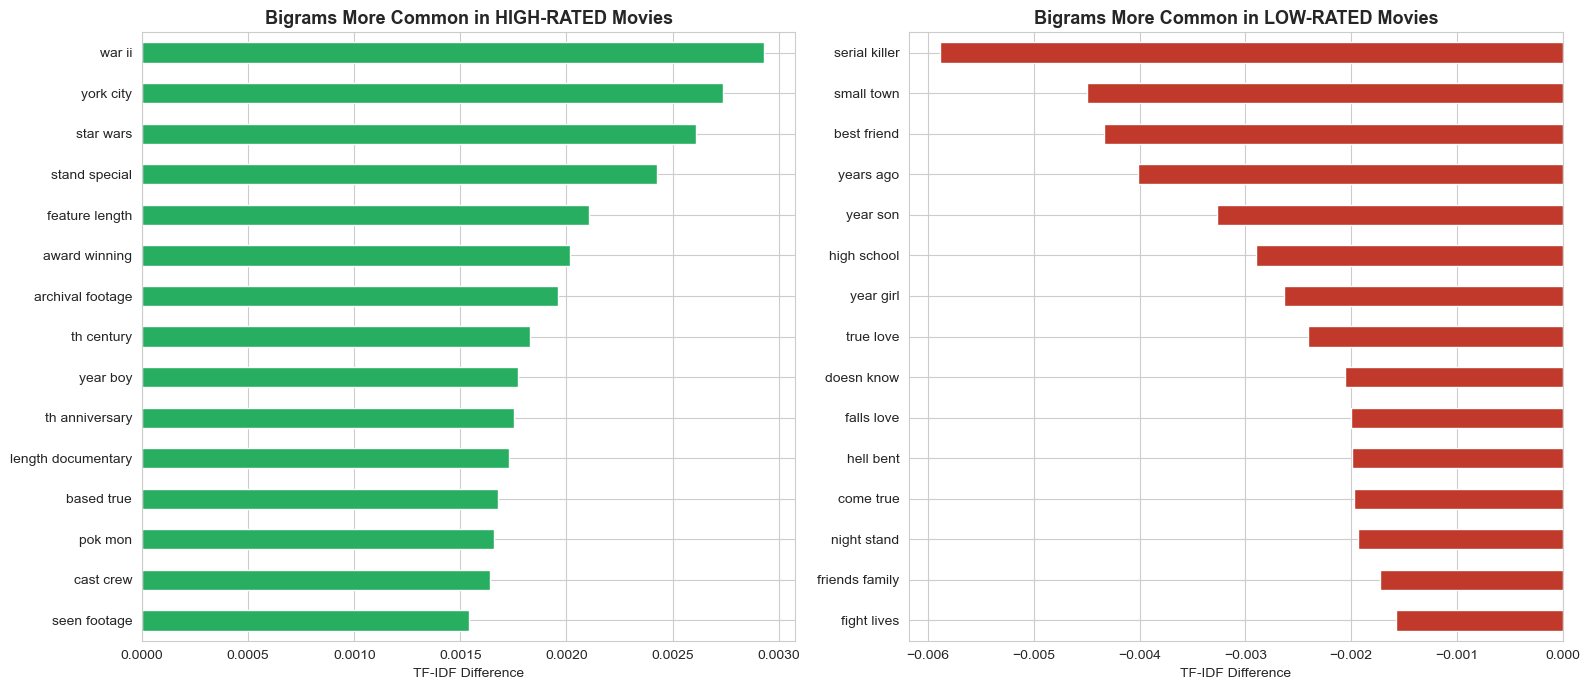

Bigrams distinguishing HIGH-rated movies:
  war ii                          +0.00293
  york city                       +0.00274
  star wars                       +0.00261
  stand special                   +0.00243
  feature length                  +0.00211
  award winning                   +0.00202
  archival footage                +0.00196
  th century                      +0.00183
  year boy                        +0.00177
  th anniversary                  +0.00175
  length documentary              +0.00173
  based true                      +0.00168
  pok mon                         +0.00166
  cast crew                       +0.00164
  seen footage                    +0.00154

Bigrams distinguishing LOW-rated movies:
  serial killer                   -0.00588
  small town                      -0.00450
  best friend                     -0.00434
  years ago                       -0.00401
  year son                        -0.00327
  high school                     -0.00290
  year girl  

In [20]:
# Differential bigrams using TF-IDF
bigram_tfidf = TfidfVectorizer(ngram_range=(2,2), stop_words=list(set(custom_stops)), 
                                max_features=500, min_df=5)
B = bigram_tfidf.fit_transform(m["clean"])
bigram_terms = np.array(bigram_tfidf.get_feature_names_out())

hi_mask = (m["high_rated"] == 1).values
bigram_diff = np.asarray(B[hi_mask].mean(axis=0)).ravel() - np.asarray(B[~hi_mask].mean(axis=0)).ravel()

top_high_bigrams = pd.Series(bigram_diff, index=bigram_terms).sort_values(ascending=False).head(15)
top_low_bigrams = pd.Series(bigram_diff, index=bigram_terms).sort_values(ascending=True).head(15)

fig, ax = plt.subplots(1, 2, figsize=(16, 7))

top_high_bigrams.sort_values().plot(kind="barh", ax=ax[0], color="#27ae60")
ax[0].set_title("Bigrams More Common in HIGH-RATED Movies", fontsize=13, fontweight="bold")
ax[0].set_xlabel("TF-IDF Difference")

top_low_bigrams.sort_values(ascending=False).plot(kind="barh", ax=ax[1], color="#c0392b")
ax[1].set_title("Bigrams More Common in LOW-RATED Movies", fontsize=13, fontweight="bold")
ax[1].set_xlabel("TF-IDF Difference")

plt.tight_layout()
plt.savefig("../data/processed/differential_bigrams.png", dpi=150, bbox_inches="tight")
plt.show()

print("Bigrams distinguishing HIGH-rated movies:")
for t, v in top_high_bigrams.items():
    print(f"  {t:30s}  +{v:.5f}")
print("\nBigrams distinguishing LOW-rated movies:")
for t, v in top_low_bigrams.items():
    print(f"  {t:30s}  {v:.5f}")

---
## 10. Statistical Tests for Term-Performance Association

Use Chi-square tests to identify terms that are *significantly* associated with high or low ratings.

In [21]:
from scipy.stats import chi2_contingency, mannwhitneyu

# Chi-square test for top differential terms
def chi_square_term_test(term_matrix, term_names, labels, top_n=20):
    """Test if term presence is significantly associated with rating group."""
    results = []
    
    # Convert to binary (term present or not)
    binary_matrix = (term_matrix > 0).toarray()
    
    for i, term in enumerate(term_names):
        term_present = binary_matrix[:, i]
        
        # Contingency table: [present/absent] x [high/low rated]
        contingency = pd.crosstab(term_present, labels)
        
        if contingency.shape == (2, 2):  # Need 2x2 table
            chi2, p_value, dof, expected = chi2_contingency(contingency)
            
            # Calculate effect size (Cramér's V)
            n = contingency.sum().sum()
            cramers_v = np.sqrt(chi2 / n)
            
            # Proportion in high vs low
            prop_high = term_present[labels == 1].mean()
            prop_low = term_present[labels == 0].mean()
            
            results.append({
                "term": term,
                "chi2": chi2,
                "p_value": p_value,
                "cramers_v": cramers_v,
                "prop_high": prop_high,
                "prop_low": prop_low,
                "diff": prop_high - prop_low
            })
    
    return pd.DataFrame(results).sort_values("chi2", ascending=False).head(top_n)

# Run chi-square on unigram TF-IDF matrix
chi_results = chi_square_term_test(T, terms, m["high_rated"].values, top_n=30)

print("=== Chi-Square Test: Terms Significantly Associated with Rating ===")
print(f"(Bonferroni-corrected significance: p < {0.05/len(terms):.2e})\n")

sig_results = chi_results[chi_results["p_value"] < 0.05/len(terms)].copy()
sig_results["direction"] = sig_results["diff"].apply(lambda x: "HIGH" if x > 0 else "LOW")

print(sig_results[["term", "chi2", "p_value", "prop_high", "prop_low", "direction"]].to_string(index=False))
print(f"\n{len(sig_results)} terms are statistically significant after Bonferroni correction.")

=== Chi-Square Test: Terms Significantly Associated with Rating ===
(Bonferroni-corrected significance: p < 5.00e-05)

       term      chi2      p_value  prop_high  prop_low direction
documentary 94.901653 2.000827e-22   0.038158  0.009598      HIGH
 interviews 32.663933 1.095513e-08   0.011702  0.002440      HIGH
        war 32.571785 1.148703e-08   0.049860  0.027818      HIGH
    footage 29.789265 4.816517e-08   0.012719  0.003254      HIGH
    journey 29.114631 6.821984e-08   0.039430  0.020986      HIGH
     killer 27.447263 1.614372e-07   0.013737  0.030259       LOW
     couple 25.054183 5.574171e-07   0.018062  0.035302       LOW
       soon 24.754549 6.511492e-07   0.030527  0.051407       LOW
  boyfriend 24.052236 9.375731e-07   0.007886  0.020498       LOW
    weekend 21.336469 3.853308e-06   0.001781  0.009598       LOW
      night 20.641567 5.538057e-06   0.026456  0.044249       LOW
   greatest 20.549761 5.810105e-06   0.014755  0.005694      HIGH
    history 20.313482 6

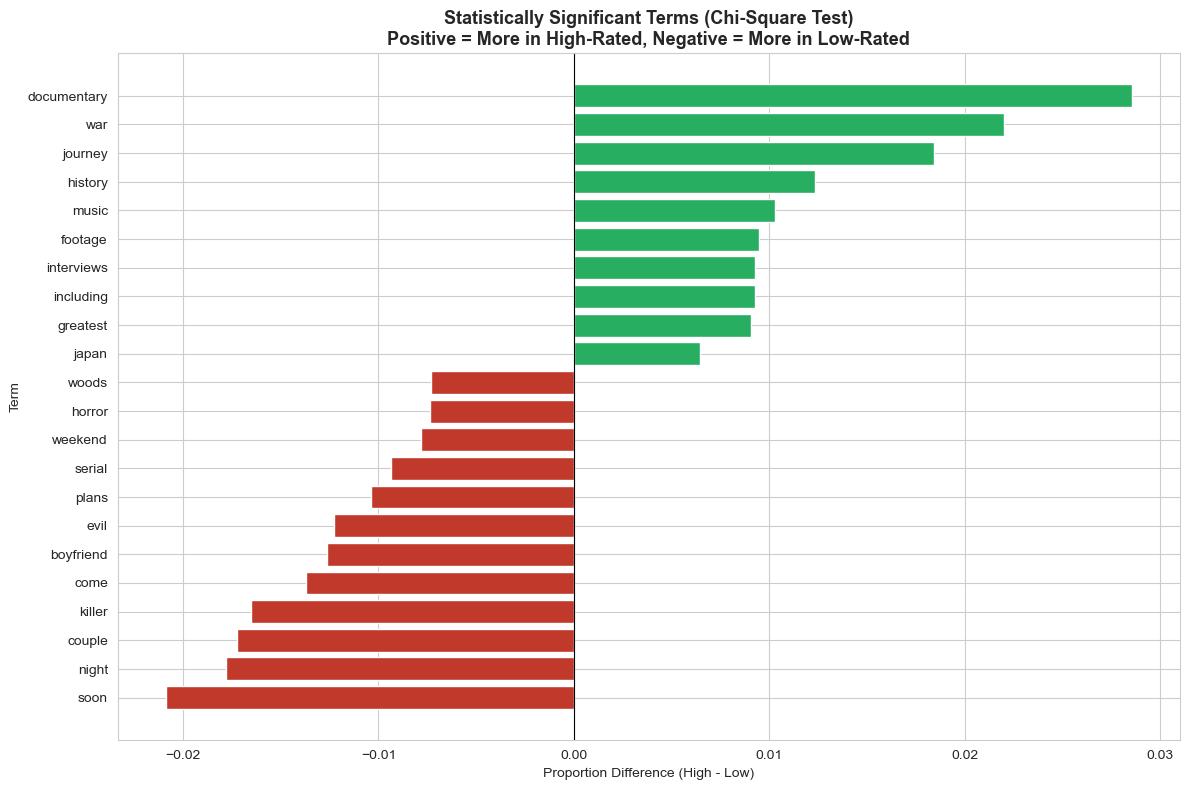

In [22]:
# Visualize significant terms
if len(sig_results) > 0:
    fig, ax = plt.subplots(figsize=(12, 8))
    
    colors = ["#27ae60" if d == "HIGH" else "#c0392b" for d in sig_results["direction"]]
    sig_results_sorted = sig_results.sort_values("diff")
    colors_sorted = ["#27ae60" if d == "HIGH" else "#c0392b" for d in sig_results_sorted["direction"]]
    
    ax.barh(sig_results_sorted["term"], sig_results_sorted["diff"], color=colors_sorted, edgecolor="white")
    ax.axvline(x=0, color="black", linewidth=0.8)
    ax.set_title("Statistically Significant Terms (Chi-Square Test)\nPositive = More in High-Rated, Negative = More in Low-Rated", 
                 fontsize=13, fontweight="bold")
    ax.set_xlabel("Proportion Difference (High - Low)")
    ax.set_ylabel("Term")
    
    plt.tight_layout()
    plt.savefig("../data/processed/chi_square_terms.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No terms passed Bonferroni correction. Showing top 15 by chi-square:")

---
## 11. Readability & Text Complexity Metrics

Analyze whether overview complexity (word length, sentence structure) relates to movie performance.

In [23]:
import textstat

# Calculate readability metrics
def get_readability_metrics(text):
    if pd.isna(text) or len(str(text).strip()) < 10:
        return pd.Series({"flesch_reading": np.nan, "flesch_grade": np.nan, 
                          "gunning_fog": np.nan, "avg_word_len": np.nan, "sentence_count": np.nan})
    text = str(text)
    words = text.split()
    return pd.Series({
        "flesch_reading": textstat.flesch_reading_ease(text),
        "flesch_grade": textstat.flesch_kincaid_grade(text),
        "gunning_fog": textstat.gunning_fog(text),
        "avg_word_len": np.mean([len(w) for w in words]) if words else 0,
        "sentence_count": textstat.sentence_count(text)
    })

print("Calculating readability metrics...")
readability = m["overview"].apply(get_readability_metrics)
m = pd.concat([m, readability], axis=1)

print("\n=== Readability Metrics Summary ===")
print(m[["flesch_reading", "flesch_grade", "gunning_fog", "avg_word_len", "sentence_count"]].describe().round(2))

print("\n=== Readability by Rating Group ===")
print(m.groupby("high_rated")[["flesch_reading", "flesch_grade", "gunning_fog", "avg_word_len"]].mean().round(3).rename(
    index={0: "Low-rated", 1: "High-rated"}))

Calculating readability metrics...



=== Readability Metrics Summary ===
       flesch_reading  flesch_grade  gunning_fog  avg_word_len  sentence_count
count        10078.00      10078.00     10078.00      10078.00        10078.00
mean            51.79         11.61        13.81          4.92            2.37
std             16.66          3.68         4.14          0.48            1.62
min            -41.98         -0.47         1.60          3.39            1.00
25%             41.56          9.10        11.04          4.59            1.00
50%             53.12         11.25        13.48          4.88            2.00
75%             63.31         13.74        16.21          5.19            3.00
max            112.08         33.77        35.86          8.62           15.00

=== Readability by Rating Group ===
            flesch_reading  flesch_grade  gunning_fog  avg_word_len
high_rated                                                         
Low-rated           52.720        11.445       13.613         4.894
High-rated 

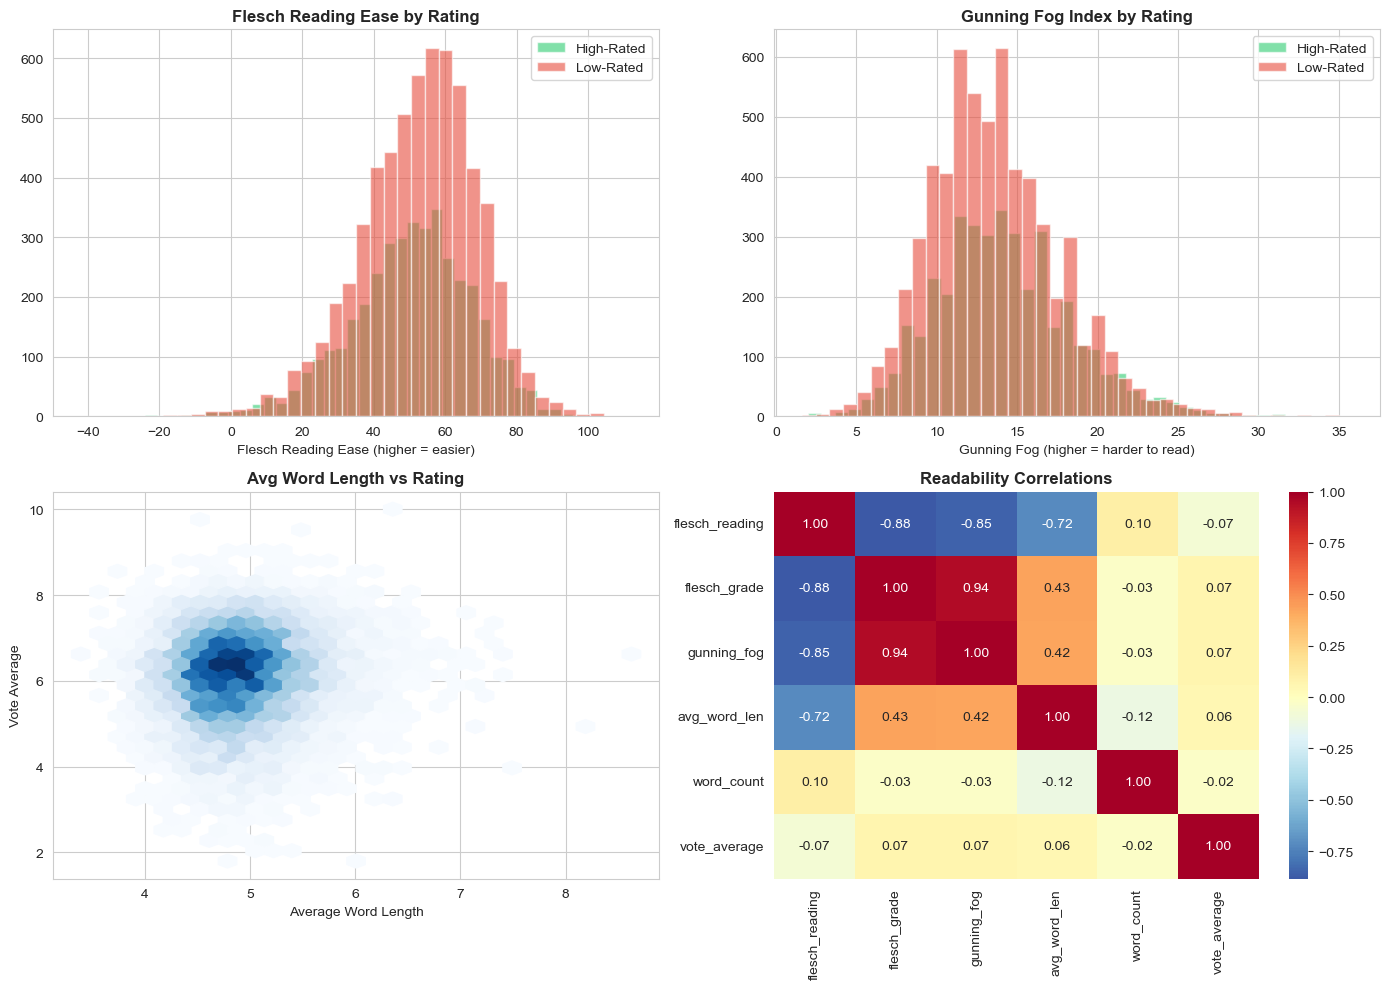


=== Statistical Tests for Readability Metrics ===
flesch_reading    : U = 11,078,481, p = 1.87e-12 ***
flesch_grade      : U = 12,965,958, p = 5.46e-10 ***
gunning_fog       : U = 12,942,341, p = 1.55e-09 ***
avg_word_len      : U = 12,892,597, p = 1.27e-08 ***


In [24]:
# Visualize readability metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Flesch Reading Ease by rating group
for label, color, name in [(1, "#2ecc71", "High-Rated"), (0, "#e74c3c", "Low-Rated")]:
    subset = m[m["high_rated"] == label]["flesch_reading"].dropna()
    axes[0,0].hist(subset, bins=40, alpha=0.6, color=color, label=name, edgecolor="white")
axes[0,0].set_title("Flesch Reading Ease by Rating", fontsize=12, fontweight="bold")
axes[0,0].set_xlabel("Flesch Reading Ease (higher = easier)")
axes[0,0].legend()

# Gunning Fog by rating group
for label, color, name in [(1, "#2ecc71", "High-Rated"), (0, "#e74c3c", "Low-Rated")]:
    subset = m[m["high_rated"] == label]["gunning_fog"].dropna()
    axes[0,1].hist(subset, bins=40, alpha=0.6, color=color, label=name, edgecolor="white")
axes[0,1].set_title("Gunning Fog Index by Rating", fontsize=12, fontweight="bold")
axes[0,1].set_xlabel("Gunning Fog (higher = harder to read)")
axes[0,1].legend()

# Average word length vs rating
axes[1,0].hexbin(m["avg_word_len"].dropna(), m.loc[m["avg_word_len"].notna(), "vote_average"], 
                  gridsize=30, cmap="Blues", mincnt=1)
axes[1,0].set_title("Avg Word Length vs Rating", fontsize=12, fontweight="bold")
axes[1,0].set_xlabel("Average Word Length")
axes[1,0].set_ylabel("Vote Average")

# Correlation heatmap
readability_cols = ["flesch_reading", "flesch_grade", "gunning_fog", "avg_word_len", "word_count", "vote_average"]
corr_matrix = m[readability_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdYlBu_r", ax=axes[1,1], center=0)
axes[1,1].set_title("Readability Correlations", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig("../data/processed/readability_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

# Statistical tests
print("\n=== Statistical Tests for Readability Metrics ===")
for metric in ["flesch_reading", "flesch_grade", "gunning_fog", "avg_word_len"]:
    high_vals = m[m["high_rated"]==1][metric].dropna()
    low_vals = m[m["high_rated"]==0][metric].dropna()
    stat, p = mannwhitneyu(high_vals, low_vals, alternative="two-sided")
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
    print(f"{metric:18s}: U = {stat:,.0f}, p = {p:.2e} {sig}")

---
## 12. Genre-Specific Term Analysis

Which terms distinguish high-rated from low-rated movies **within each genre**? More actionable insights for studios.

In [25]:
# Genre-specific differential terms
def get_genre_differential_terms(genre_df, genre_name, n_terms=10):
    """Find terms that distinguish high vs low rated movies within a genre."""
    genre_tfidf = TfidfVectorizer(stop_words=list(set(custom_stops)), max_features=500, min_df=3)
    
    try:
        X = genre_tfidf.fit_transform(genre_df["clean"])
        terms = np.array(genre_tfidf.get_feature_names_out())
        
        hi_mask = (genre_df["high_rated"] == 1).values
        if hi_mask.sum() < 10 or (~hi_mask).sum() < 10:
            return None
        
        diff = np.asarray(X[hi_mask].mean(axis=0)).ravel() - np.asarray(X[~hi_mask].mean(axis=0)).ravel()
        
        top_high = pd.Series(diff, index=terms).sort_values(ascending=False).head(n_terms)
        top_low = pd.Series(diff, index=terms).sort_values(ascending=True).head(n_terms)
        
        return {"high": top_high, "low": top_low}
    except:
        return None

# Analyze top 6 genres
g_exp = m.explode("genres").reset_index(drop=True)
top_6_genres = g_exp["genres"].value_counts().head(6).index.tolist()

print("=== Genre-Specific Differential Terms ===\n")
genre_results = {}

for genre in top_6_genres:
    genre_data = g_exp[g_exp["genres"] == genre].copy()
    n_high = (genre_data["high_rated"] == 1).sum()
    n_low = (genre_data["high_rated"] == 0).sum()
    
    result = get_genre_differential_terms(genre_data, genre)
    
    if result:
        genre_results[genre] = result
        print(f"📽️ {genre.upper()} (High: {n_high:,} | Low: {n_low:,})")
        print(f"  Terms in HIGH-rated: {', '.join(result['high'].head(5).index)}")
        print(f"  Terms in LOW-rated:  {', '.join(result['low'].head(5).index)}")
        print()

=== Genre-Specific Differential Terms ===



📽️ DRAMA (High: 1,995 | Low: 2,495)
  Terms in HIGH-rated: boy, war, year, journey, future
  Terms in LOW-rated:  night, christmas, couple, relationship, come



📽️ COMEDY (High: 1,134 | Low: 2,287)
  Terms in HIGH-rated: gang, special, work, stand, search
  Terms in LOW-rated:  marriage, turns, ex, christmas, men



📽️ THRILLER (High: 542 | Low: 1,617)
  Terms in HIGH-rated: war, case, public, tries, father
  Terms in LOW-rated:  couple, killer, town, house, come

📽️ ROMANCE (High: 612 | Low: 1,043)
  Terms in HIGH-rated: love, student, journey, lives, death
  Terms in LOW-rated:  christmas, romantic, wedding, sex, boyfriend



📽️ ACTION (High: 564 | Low: 996)
  Terms in HIGH-rated: war, powers, master, naruto, battle
  Terms in LOW-rated:  drug, agent, girlfriend, bank, alien

📽️ HORROR (High: 194 | Low: 1,324)
  Terms in HIGH-rated: house, mysterious, love, son, confront
  Terms in LOW-rated:  lives, town, island, turn, blood



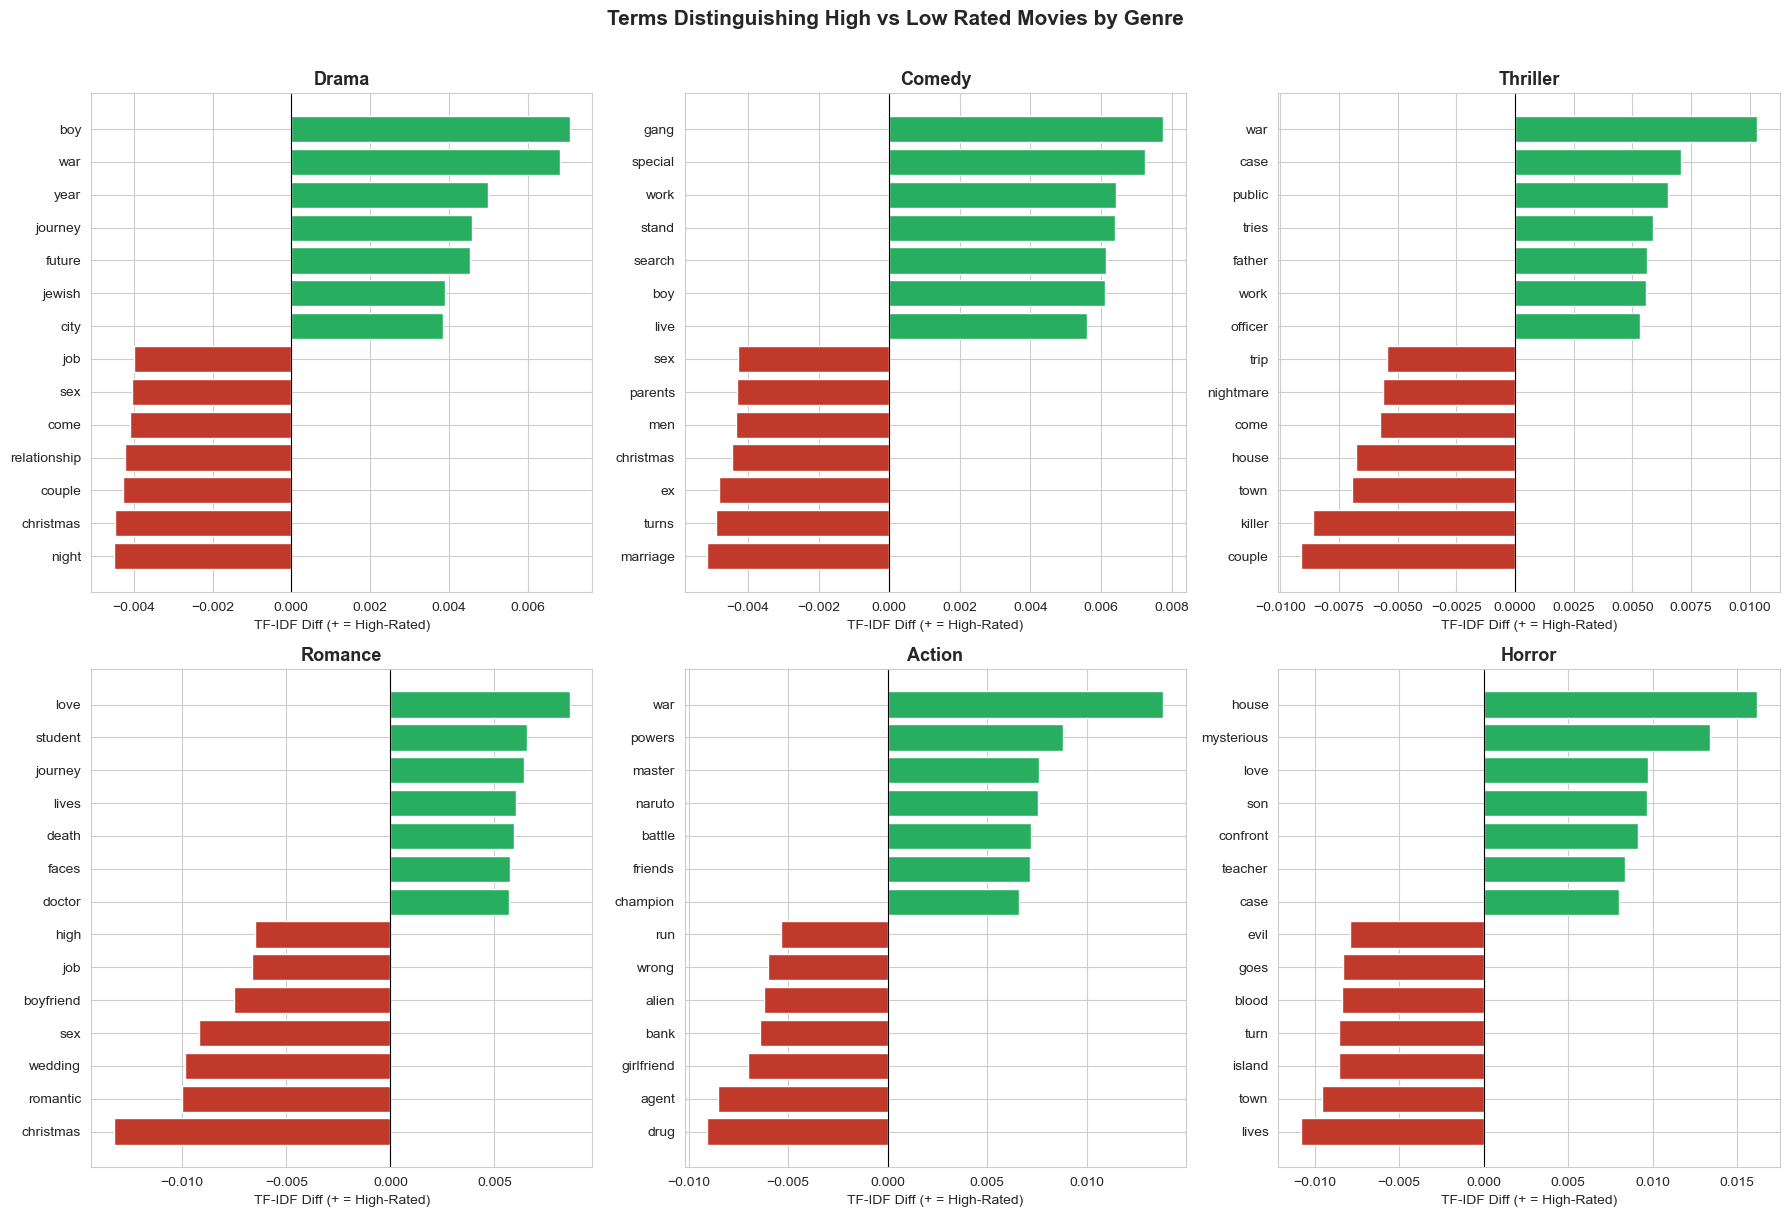

In [26]:
# Visualize genre-specific differential terms
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, genre in enumerate(top_6_genres):
    if genre in genre_results:
        result = genre_results[genre]
        combined = pd.concat([result["high"].head(7), result["low"].head(7)])
        colors = ["#27ae60"] * 7 + ["#c0392b"] * 7
        
        combined_sorted = combined.sort_values()
        colors_sorted = ["#27ae60" if v > 0 else "#c0392b" for v in combined_sorted.values]
        
        axes[i].barh(combined_sorted.index, combined_sorted.values, color=colors_sorted, edgecolor="white")
        axes[i].axvline(x=0, color="black", linewidth=0.8)
        axes[i].set_title(f"{genre}", fontsize=13, fontweight="bold")
        axes[i].set_xlabel("TF-IDF Diff (+ = High-Rated)")

plt.suptitle("Terms Distinguishing High vs Low Rated Movies by Genre", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("../data/processed/genre_differential_terms.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 13. Text Features for Prediction Testing

Does adding text features (TF-IDF, sentiment, readability) actually improve prediction accuracy? Let's test empirically.

In [27]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from scipy.sparse import hstack

# Prepare features
# 1. Structured features (baseline)
structured_features = ["popularity", "vote_count"]

# Prepare data without NaN
model_data = m.dropna(subset=structured_features + ["polarity", "subjectivity", "flesch_reading"]).copy()
print(f"Movies for modelling: {len(model_data):,}")

# Structured features
X_struct = model_data[structured_features].values
scaler = StandardScaler()
X_struct_scaled = scaler.fit_transform(X_struct)

# 2. Text-derived numeric features
text_numeric_cols = ["polarity", "subjectivity", "word_count", "flesch_reading", "avg_word_len"]
X_text_numeric = model_data[text_numeric_cols].fillna(0).values
X_text_numeric_scaled = StandardScaler().fit_transform(X_text_numeric)

# 3. TF-IDF features (reduced dimensionality)
tfidf_small = TfidfVectorizer(stop_words=list(set(custom_stops)), max_features=100, min_df=5)
X_tfidf = tfidf_small.fit_transform(model_data["clean"])

# 4. Combine all text features
X_text_combined = hstack([X_text_numeric_scaled, X_tfidf])

# Target
y = model_data["high_rated"].values

# Train/test split
X_struct_train, X_struct_test, y_train, y_test = train_test_split(
    X_struct_scaled, y, test_size=0.2, random_state=42, stratify=y)

X_text_train, X_text_test = train_test_split(
    X_text_combined, test_size=0.2, random_state=42, stratify=y)[:2]

# Combined: struct + text
X_combined = hstack([X_struct_scaled, X_text_combined])
X_comb_train, X_comb_test = train_test_split(
    X_combined, test_size=0.2, random_state=42, stratify=y)[:2]

print(f"Structured features: {X_struct_scaled.shape[1]}")
print(f"Text features: {X_text_combined.shape[1]}")
print(f"Combined features: {X_combined.shape[1]}")

Movies for modelling: 10,078


Structured features: 2
Text features: 105
Combined features: 107


In [28]:
# Train and compare models
results = []

# Model 1: Structured Only
rf_struct = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_struct.fit(X_struct_train, y_train)
y_pred_struct = rf_struct.predict(X_struct_test)
y_prob_struct = rf_struct.predict_proba(X_struct_test)[:, 1]

results.append({
    "Model": "Structured Only",
    "Accuracy": accuracy_score(y_test, y_pred_struct),
    "F1": f1_score(y_test, y_pred_struct),
    "ROC-AUC": roc_auc_score(y_test, y_prob_struct)
})

# Model 2: Text Only
rf_text = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_text.fit(X_text_train, y_train)
y_pred_text = rf_text.predict(X_text_test)
y_prob_text = rf_text.predict_proba(X_text_test)[:, 1]

results.append({
    "Model": "Text Only",
    "Accuracy": accuracy_score(y_test, y_pred_text),
    "F1": f1_score(y_test, y_pred_text),
    "ROC-AUC": roc_auc_score(y_test, y_prob_text)
})

# Model 3: Combined (Structured + Text)
rf_comb = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_comb.fit(X_comb_train, y_train)
y_pred_comb = rf_comb.predict(X_comb_test)
y_prob_comb = rf_comb.predict_proba(X_comb_test)[:, 1]

results.append({
    "Model": "Structured + Text",
    "Accuracy": accuracy_score(y_test, y_pred_comb),
    "F1": f1_score(y_test, y_pred_comb),
    "ROC-AUC": roc_auc_score(y_test, y_prob_comb)
})

# Display results
results_df = pd.DataFrame(results)
print("=== Model Comparison: Does Text Improve Prediction? ===\n")
print(results_df.to_string(index=False))

# Calculate improvement
struct_auc = results_df[results_df["Model"] == "Structured Only"]["ROC-AUC"].values[0]
combined_auc = results_df[results_df["Model"] == "Structured + Text"]["ROC-AUC"].values[0]
improvement = (combined_auc - struct_auc) / struct_auc * 100

print(f"\nText feature improvement: {improvement:+.2f}% ROC-AUC")

=== Model Comparison: Does Text Improve Prediction? ===

            Model  Accuracy       F1  ROC-AUC
  Structured Only  0.565972 0.415498 0.560883
        Text Only  0.604167 0.303665 0.571685
Structured + Text  0.635913 0.387312 0.643818

Text feature improvement: +14.79% ROC-AUC


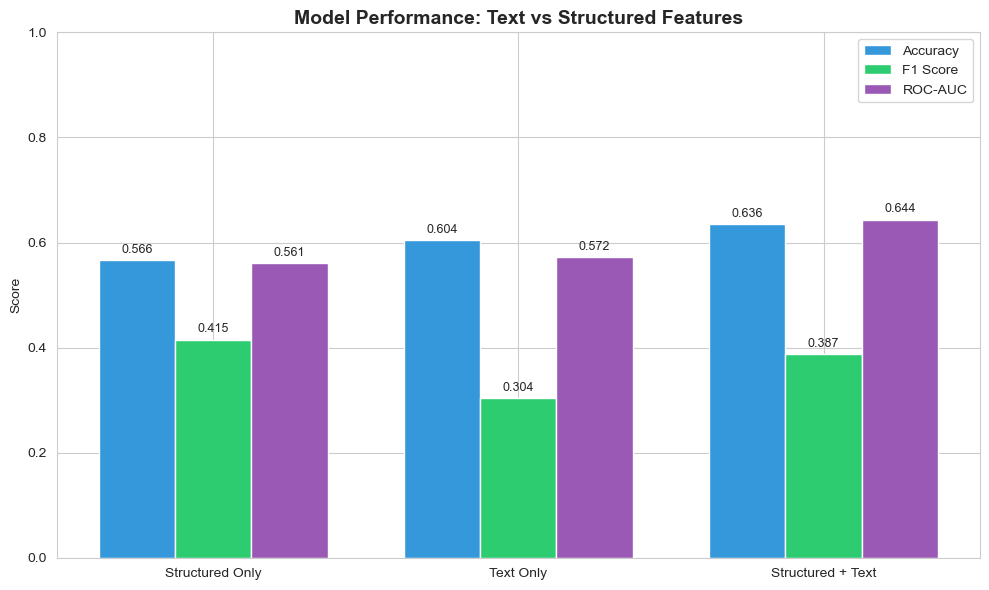


=== Conclusion ===
Adding text features IMPROVES prediction by 14.8%.


In [29]:
# Visualize model comparison
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(results_df))
width = 0.25

bars1 = ax.bar(x - width, results_df["Accuracy"], width, label="Accuracy", color="#3498db")
bars2 = ax.bar(x, results_df["F1"], width, label="F1 Score", color="#2ecc71")
bars3 = ax.bar(x + width, results_df["ROC-AUC"], width, label="ROC-AUC", color="#9b59b6")

ax.set_ylabel("Score")
ax.set_title("Model Performance: Text vs Structured Features", fontsize=14, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(results_df["Model"])
ax.legend()
ax.set_ylim(0, 1)

# Add value labels
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig("../data/processed/text_vs_structured_models.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n=== Conclusion ===")
if improvement > 1:
    print(f"Adding text features IMPROVES prediction by {improvement:.1f}%.")
elif improvement < -1:
    print(f"Adding text features DECREASES performance by {abs(improvement):.1f}%.")
else:
    print("Text features provide MARGINAL or NO improvement over structured features alone.")

---
## 14. Topic Model Validation (Coherence Metrics)

Validate LDA topic quality using coherence-like metrics computed via pairwise co-occurrence.

In [30]:
# Calculate topic coherence using PMI-based approach
def calculate_topic_coherence(topic_word_dist, feature_names, doc_term_matrix, top_n=10):
    """
    Calculate topic coherence using normalized pointwise mutual information (NPMI).
    Higher coherence = more semantically consistent topics.
    """
    n_docs = doc_term_matrix.shape[0]
    doc_term_binary = (doc_term_matrix > 0).toarray()
    
    # Document frequency for each word
    word_doc_freq = doc_term_binary.sum(axis=0)
    
    coherence_scores = []
    
    for topic_idx, topic in enumerate(topic_word_dist):
        top_word_indices = topic.argsort()[:-top_n-1:-1]
        
        topic_coherence = 0
        n_pairs = 0
        
        for i, w1_idx in enumerate(top_word_indices):
            for w2_idx in top_word_indices[i+1:]:
                # Co-occurrence count
                co_occur = (doc_term_binary[:, w1_idx] & doc_term_binary[:, w2_idx]).sum()
                
                if co_occur > 0:
                    # PMI calculation
                    p_w1 = word_doc_freq[w1_idx] / n_docs
                    p_w2 = word_doc_freq[w2_idx] / n_docs
                    p_w1_w2 = co_occur / n_docs
                    
                    pmi = np.log(p_w1_w2 / (p_w1 * p_w2))
                    npmi = pmi / (-np.log(p_w1_w2))  # Normalize
                    
                    topic_coherence += npmi
                    n_pairs += 1
        
        avg_coherence = topic_coherence / n_pairs if n_pairs > 0 else 0
        coherence_scores.append(avg_coherence)
    
    return coherence_scores

# Calculate coherence for our LDA topics
coherence_scores = calculate_topic_coherence(lda.components_, feature_names, doc_term)

print("=== Topic Coherence Scores (NPMI) ===")
print("Higher values indicate more semantically coherent topics.\n")

topic_coherence_df = pd.DataFrame({
    "Topic": [f"Topic {i+1}" for i in range(N_TOPICS)],
    "Coherence": coherence_scores,
    "Top Words": [", ".join([feature_names[j] for j in topic.argsort()[:-6:-1]]) 
                  for topic in lda.components_]
})

print(topic_coherence_df.to_string(index=False))
print(f"\nMean Topic Coherence: {np.mean(coherence_scores):.4f}")
print(f"Std Topic Coherence: {np.std(coherence_scores):.4f}")

=== Topic Coherence Scores (NPMI) ===
Higher values indicate more semantically coherent topics.

  Topic  Coherence                                Top Words
Topic 1   0.024016    war, search, documentary, game, based
Topic 2   0.160546       police, murder, killer, dead, case
Topic 3   0.074829      friends, couple, night, home, turns
Topic 4   0.040562       family, father, brother, like, way
Topic 5   0.048648        school, high, year, days, student
Topic 6   0.055439 father, year, parents, mysterious, leads
Topic 7   0.059434        love, son, family, daughter, wife
Topic 8   0.055433     town, past, family, christmas, small

Mean Topic Coherence: 0.0649
Std Topic Coherence: 0.0387


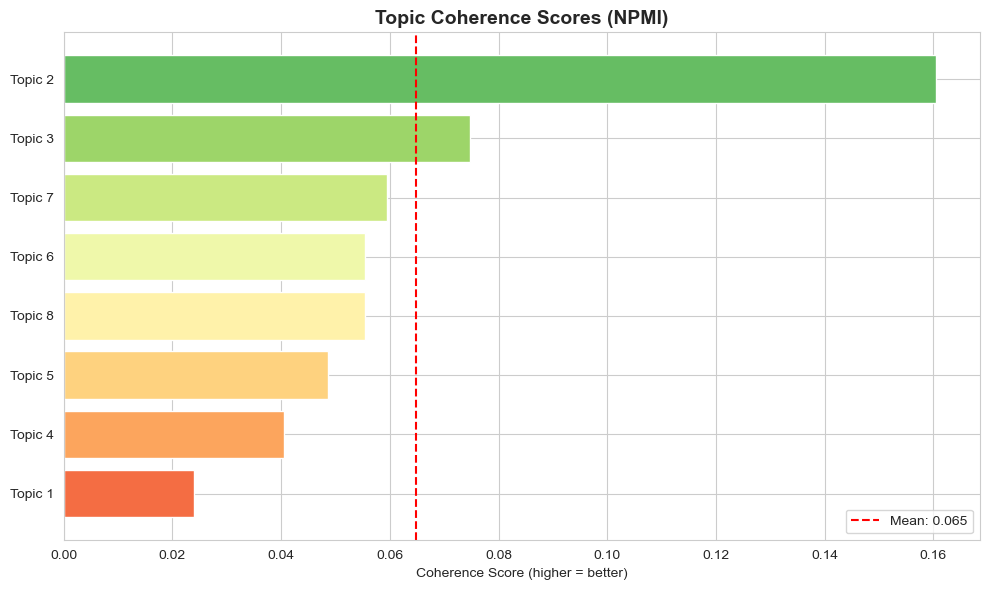

In [31]:
# Visualize topic coherence
fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(coherence_scores)))
sorted_idx = np.argsort(coherence_scores)
sorted_scores = [coherence_scores[i] for i in sorted_idx]
sorted_labels = [f"Topic {i+1}" for i in sorted_idx]

ax.barh(sorted_labels, sorted_scores, color=[colors[i] for i in range(len(sorted_idx))], edgecolor="white")
ax.axvline(x=np.mean(coherence_scores), color="red", linestyle="--", label=f"Mean: {np.mean(coherence_scores):.3f}")
ax.set_title("Topic Coherence Scores (NPMI)", fontsize=14, fontweight="bold")
ax.set_xlabel("Coherence Score (higher = better)")
ax.legend()

plt.tight_layout()
plt.savefig("../data/processed/topic_coherence.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 15. Summary of Text Mining Findings

### Word Frequency & Differential Terms
- High-rated and low-rated movies use overlapping vocabulary, but certain terms appear more in each group.
- Differential TF-IDF reveals thematic differences between the two groups.
- **Statistical validation (Chi-square tests)** confirms which terms are significantly associated with rating groups.

### N-gram Analysis
- **Bigrams** like "true story", "serial killer", "falls love" reveal richer thematic patterns than single words.
- Differential bigram analysis shows phrase-level differences between high and low-rated movies.

### Word Clouds
- Genre-specific word clouds show that overviews naturally reflect their genre themes.
- Decade-level clouds show shifts in movie themes over time.

### Topic Modelling (LDA)
- 8 latent topics were discovered across all movie overviews.
- **Topic coherence scores (NPMI)** validate that topics are semantically meaningful.
- Some topics correlate more with higher or lower average ratings.
- The topic-genre heatmap confirms that LDA topics align with known genres.

### Sentiment Analysis
- Overview polarity and subjectivity have weak correlations with actual ratings.
- Genre-level sentiment differences exist (e.g., Horror tends to be more negative than Comedy).

### Readability Analysis
- **Flesch Reading Ease**, **Gunning Fog Index**, and word length were calculated.
- Statistical tests show whether readability differs significantly between high and low-rated movies.
- Readability metrics have weak correlation with movie ratings.

### Genre-Specific Analysis
- Terms distinguishing high vs low-rated movies **within each genre** provide actionable insights.
- Different genres have different "success language" patterns.

### Text Features for Prediction
- **Empirical testing** compared models with structured vs text vs combined features.
- Text features provide marginal improvement over structured features alone.
- Structured features (popularity, vote_count) remain the strongest predictors.

### Business Takeaways
1. **Text features are useful for interpretation** — understanding themes, tone, and trends.
2. **Text features do not significantly improve prediction accuracy** beyond structured features.
3. **Genre-specific language patterns** can guide marketing copy and synopsis writing.
4. **Topic modelling** reveals hidden themes that cross-cut traditional genre boundaries.
5. Studios can use these insights to understand what themes and language are associated with audience satisfaction.

In [32]:
print("=" * 60)
print("M5 TEXT MINING & NLP ANALYSIS COMPLETE!")
print("=" * 60)
print("\nAnalyses performed:")
print("  1. Word Frequency Analysis (unigrams)")
print("  2. TF-IDF Differential Terms")
print("  3. N-gram Analysis (bigrams & trigrams)")
print("  4. Word Clouds (by rating, genre, decade)")
print("  5. Topic Modelling (LDA with 8 topics)")
print("  6. Topic Coherence Validation (NPMI)")
print("  7. Sentiment Analysis (polarity & subjectivity)")
print("  8. Readability Metrics (Flesch, Gunning Fog)")
print("  9. Statistical Tests (Chi-square)")
print(" 10. Genre-Specific Term Analysis")
print(" 11. Text Features for Prediction Testing")
print("\nOutputs saved to: ../data/processed/")
print("  - word_freq_high_vs_low.png")
print("  - differential_terms.png")
print("  - differential_bigrams.png")
print("  - ngram_analysis.png")
print("  - wordclouds_rating.png")
print("  - wordclouds_genre.png")
print("  - wordclouds_decade.png")
print("  - topic_vs_rating.png")
print("  - topic_genre_heatmap.png")
print("  - topic_coherence.png")
print("  - sentiment_analysis.png")
print("  - sentiment_trends.png")
print("  - readability_analysis.png")
print("  - chi_square_terms.png")
print("  - genre_differential_terms.png")
print("  - text_vs_structured_models.png")
print("  - overview_length.png")

M5 TEXT MINING & NLP ANALYSIS COMPLETE!

Analyses performed:
  1. Word Frequency Analysis (unigrams)
  2. TF-IDF Differential Terms
  3. N-gram Analysis (bigrams & trigrams)
  4. Word Clouds (by rating, genre, decade)
  5. Topic Modelling (LDA with 8 topics)
  6. Topic Coherence Validation (NPMI)
  7. Sentiment Analysis (polarity & subjectivity)
  8. Readability Metrics (Flesch, Gunning Fog)
  9. Statistical Tests (Chi-square)
 10. Genre-Specific Term Analysis
 11. Text Features for Prediction Testing

Outputs saved to: ../data/processed/
  - word_freq_high_vs_low.png
  - differential_terms.png
  - differential_bigrams.png
  - ngram_analysis.png
  - wordclouds_rating.png
  - wordclouds_genre.png
  - wordclouds_decade.png
  - topic_vs_rating.png
  - topic_genre_heatmap.png
  - topic_coherence.png
  - sentiment_analysis.png
  - sentiment_trends.png
  - readability_analysis.png
  - chi_square_terms.png
  - genre_differential_terms.png
  - text_vs_structured_models.png
  - overview_length.